
# STRATUM — Explainable Artificial Intelligence

## Phase 3 — Step 3.7

### Background

Previous STRATUM investigations established
independently selected virtual metrology models
for mean film thickness and sheet resistance.

Predictive performance alone does not explain
the model's reliance on process inputs or
individual prediction behaviour.

This investigation applies complementary
model-explanation techniques.

### Objectives

1. Reproduce both frozen regression models.

2. Extract XGBoost gain-based feature importance.

3. Evaluate raw-input permutation importance.

4. Calculate native XGBoost TreeSHAP contributions.

5. Convert resistance contributions into
   the original target scale.

6. Verify additive prediction reconstruction.

7. Compare global predictor importance across
   both material-property models.

8. Investigate individual wafer predictions.

9. Preserve structured explanation evidence
   for application and LLM integration.

### Explainability Methods

- Normalised XGBoost average-gain importance.
- Repeated permutation importance.
- Native TreeSHAP feature contributions.

### Evaluation Protocol

Fit both frozen model configurations using
the eligible original training observations.

Perform global and local explainability
using the original validation partition.

Do not modify the frozen model configurations.

Final held-out targets remain reserved.

### Interpretation Restrictions

Feature importance measures model behaviour.

Feature contributions do not establish
physical causality, equipment faults,
or semiconductor process-control limits.

Local explanations are not uncertainty estimates.

The explainability investigation will not
be used for further feature elimination
or hyperparameter selection.

In [1]:

# Imports and experiment configuration

from pathlib import Path
import sys
import json
import hashlib
import time

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

import sklearn
import xgboost

from scipy.stats import spearmanr

from sklearn.inspection import (
    permutation_importance,
)

sns.set_theme(style="whitegrid")

current_dir = Path.cwd()

if (
    current_dir
    / "ml"
    / "explainability.py"
).exists():

    project_root = current_dir

elif (
    current_dir.parent
    / "ml"
    / "explainability.py"
).exists():

    project_root = current_dir.parent

else:

    raise FileNotFoundError(
        "Cannot locate STRATUM project root."
    )

if str(project_root) not in sys.path:

    sys.path.insert(
        0,

        str(project_root),
    )

from ml.data_split import (
    chronological_lot_split,
)

from ml.preprocessing import (
    get_feature_columns,
)

from ml.cross_validation import (
    prepare_chronological_data,
    purge_training_overlap,
    get_candidate_columns,
    fit_candidate_model,
)

from ml.resistance_models import (
    get_resistance_candidate_columns,
    fit_resistance_candidate,
)

from ml.evaluation import (
    evaluate_regression,
)

from ml.explainability import (
    unwrap_fitted_pipeline,
    get_transformed_feature_names,
    extract_gain_importance,
    calculate_tree_contributions,
    map_transformed_feature_to_raw,
    aggregate_raw_contributions,
    global_shap_importance,
    explain_single_prediction,
)

RANDOM_STATE = 42

PERMUTATION_REPEATS = 5

MODEL_N_JOBS = -1

PERMUTATION_N_JOBS = 1

TOP_N_FEATURES = 15

RESISTANCE_DISPLAY_SCALE = 1_000_000

TARGETS = [
    "mean_thickness",
    "mean_resistance",
]

print("STRATUM - Model Explainability")

print("Python:", sys.version.split()[0])

print("Scikit-learn:", sklearn.__version__)

print("XGBoost:", xgboost.__version__)

print("\nAll modules imported successfully!")

STRATUM - Model Explainability
Python: 3.14.3
Scikit-learn: 1.9.1
XGBoost: 3.4.1

All modules imported successfully!


## 1. Dataset and Experiment Reproducibility

Verify the dataset fingerprint and fixed
chronological partitions.

Load both frozen model configurations and
their corresponding optimisation results.

Retain the original validation population
for explainability analysis.

The final test population remains reserved.

In [2]:

# Load and verify dataset

csv_path = (
    project_root
    / "data"
    / "raw"
    / "apc_spc_AlCu_inputs_outputs.csv"
)

manifest = json.loads(
    (
        project_root
        / "docs"
        / "split_manifest.json"
    ).read_text(encoding="utf-8")
)

current_sha256 = hashlib.sha256(
    csv_path.read_bytes()
).hexdigest()

assert (
    current_sha256
    == manifest["dataset_sha256"]
)

df = pd.read_csv(
    csv_path,

    sep=";",

    skiprows=1,

    low_memory=False,
)

assert df.shape == (5208, 178)

train_df, val_df, test_df, split_info = (
    chronological_lot_split(
        df,

        test_fraction=manifest[
            "test_fraction"
        ],

        validation_fraction=manifest[
            "validation_fraction_of_development"
        ],
    )
)

assert (
    split_info
    == manifest["split_summary"]
)

apc_features, _ = get_feature_columns(df)

assert (
    apc_features
    == manifest["numeric_apc_features"]
)

train_df = prepare_chronological_data(
    train_df
)

val_df = prepare_chronological_data(
    val_df
)

assessment_train_df, assessment_purge_info = (
    purge_training_overlap(
        train_df,

        val_df,
    )
)

assert len(train_df) == 3331
assert len(val_df) == 834
assert len(test_df) == 1042

assert len(apc_features) == 110

print("Dataset fingerprint: VERIFIED")

print("Partition manifest: VERIFIED")

print("Feature schema: VERIFIED")

print(
    "\nModel training records:",
    len(assessment_train_df)
)

print(
    "Explainability observations:",
    len(val_df)
)

print(
    "Reserved test records:",
    len(test_df)
)

Dataset fingerprint: VERIFIED
Partition manifest: VERIFIED
Feature schema: VERIFIED

Model training records: 3331
Explainability observations: 834
Reserved test records: 1042


In [3]:

# Load frozen model configurations

results_dir = (
    project_root / "ml" / "results"
)

selection_files = {
    "mean_thickness": (
        "thickness_model_selection.json"
    ),

    "mean_resistance": (
        "resistance_model_selection.json"
    ),
}

optimisation_files = {
    "mean_thickness": (
        "thickness_optimisation.json"
    ),

    "mean_resistance": (
        "resistance_optimisation.json"
    ),
}

selections = {}

optimisation_results = {}

model_configs = {}

input_columns = {}

for target in TARGETS:

    selection = json.loads(
        (
            results_dir
            / selection_files[target]
        ).read_text(encoding="utf-8")
    )

    optimisation = json.loads(
        (
            results_dir
            / optimisation_files[target]
        ).read_text(encoding="utf-8")
    )

    assert (
        selection["dataset_sha256"]
        == current_sha256
    )

    assert (
        optimisation["dataset_sha256"]
        == current_sha256
    )

    assert selection["target"] == target

    assert (
        optimisation["selection"]
        == selection
    )

    assert (
        optimisation["assessment_purge_info"]
        == assessment_purge_info
    )

    candidate = selection[
        "selected_candidate"
    ]

    assert (
        candidate["algorithm"]
        == "XGBoost"
    )

    if target == "mean_thickness":

        columns = get_candidate_columns(
            candidate,

            apc_features,
        )

    else:

        columns = (
            get_resistance_candidate_columns(
                candidate,

                apc_features,
            )
        )

    selections[target] = selection

    optimisation_results[target] = (
        optimisation
    )

    model_configs[target] = candidate

    input_columns[target] = columns

    print(
        target,

        "->",

        candidate["name"],

        "| Inputs:",

        len(columns),

        "| Rounds:",

        candidate["parameters"][
            "n_estimators"
        ],
    )

assert (
    model_configs["mean_thickness"]["name"]
    == "XGB-4"
)

assert (
    model_configs["mean_resistance"]["name"]
    == "RES-XGB-2"
)

assert len(
    input_columns["mean_thickness"]
) == 110

assert len(
    input_columns["mean_resistance"]
) == 111

print("\nFrozen configurations: VERIFIED")

mean_thickness -> XGB-4 | Inputs: 110 | Rounds: 820
mean_resistance -> RES-XGB-2 | Inputs: 111 | Rounds: 837

Frozen configurations: VERIFIED


## 2. Frozen Model Reproduction

Refit the frozen thickness and resistance
configurations using their established
original training population.

Use fixed boosting-round counts.

Verify that reproduced validation metrics
agree with the preceding optimisation results
within numerical tolerances.

No model parameters are optimised.

In [4]:

# Reproduce both selected models

models = {}

predictions = {}

reproduction_rows = []

for target in TARGETS:

    candidate = model_configs[target]

    columns = input_columns[target]

    rounds = candidate["parameters"][
        "n_estimators"
    ]

    start = time.perf_counter()

    if target == "mean_thickness":

        model, fit_info = fit_candidate_model(
            candidate=candidate,

            training_data=assessment_train_df,

            apc_features=apc_features,

            target=target,

            n_jobs=MODEL_N_JOBS,

            fixed_boosting_rounds=rounds,
        )

    else:

        model, fit_info = (
            fit_resistance_candidate(
                candidate=candidate,

                training_data=assessment_train_df,

                apc_features=apc_features,

                target=target,

                n_jobs=MODEL_N_JOBS,

                fixed_boosting_rounds=rounds,
            )
        )

    elapsed = (
        time.perf_counter() - start
    )

    predicted = np.asarray(
        model.predict(
            val_df[columns]
        ),

        dtype=float,
    )

    assert np.isfinite(predicted).all()

    assert (predicted > 0).all()

    metrics = evaluate_regression(
        val_df[target],

        predicted,
    )

    reference_mae = float(
        optimisation_results[target][
            "selected_validation_mae"
        ]
    )

    reference_r2 = float(
        optimisation_results[target][
            "selected_validation_r2"
        ]
    )

    mae_difference = abs(
        metrics["MAE"]
        - reference_mae
    )

    np.testing.assert_allclose(
        metrics["MAE"],

        reference_mae,

        rtol=1e-4,

        atol=1e-12,
    )

    np.testing.assert_allclose(
        metrics["R2"],

        reference_r2,

        rtol=1e-4,

        atol=1e-6,
    )

    models[target] = model

    predictions[target] = predicted

    reproduction_rows.append({
        "Target": target,

        "Candidate": candidate["name"],

        **metrics,

        "Reference MAE": reference_mae,

        "MAE Reproduction Difference": (
            mae_difference
        ),

        "Reference R2": reference_r2,

        "Training Time (s)": elapsed,
    })

reproduction_summary = pd.DataFrame(
    reproduction_rows
)

display(
    reproduction_summary.round(10)
)

print(
    "Frozen model reproduction: PASSED"
)

,Target,Candidate,MAE,RMSE,R2,MAPE (%),Bias,Reference MAE,MAE Reproduction Difference,Reference R2,Training Time (s)
0,mean_thickness,XGB-4,1.072550,1.443448,0.650733,0.706370,-5.804488e-02,1.072550,0.0,0.650733,3.984979
1,mean_resistance,RES-XGB-2,0.000023,0.000031,0.633802,0.777569,-2.111000e-07,0.000023,0.0,0.633802,3.181357


Frozen model reproduction: PASSED


## 3. Transformed Feature Schema

Inspect the fitted preprocessing output
for both virtual metrology models.

Distinguish original APC representations,
missingness indicators, and equipment
one-hot encoded features.

Verify the mapping from transformed features
to their originating raw inputs.

In [5]:

# Inspect fitted transformed feature schemas

feature_schema_rows = []

transformed_feature_schemas = {}

for target in TARGETS:

    names = get_transformed_feature_names(
        models[target]
    )

    schema_rows = []

    for name in names:

        raw_feature = (
            map_transformed_feature_to_raw(
                name,

                apc_features,
            )
        )

        if raw_feature == "equipment":

            group = "Equipment Metadata"

        elif "missingindicator_" in name:

            group = "Missingness Indicators"

        else:

            group = "APC Measurements"

        schema_rows.append({
            "Feature": name,

            "Raw Feature": raw_feature,

            "Group": group,
        })

    schema_df = pd.DataFrame(
        schema_rows
    )

    transformed_feature_schemas[
        target
    ] = schema_df

    group_counts = (
        schema_df["Group"]
        .value_counts()
    )

    feature_schema_rows.append({
        "Target": target,

        "Raw Inputs": len(
            input_columns[target]
        ),

        "Transformed Features": len(names),

        "APC Measurements": int(
            group_counts.get(
                "APC Measurements",
                0,
            )
        ),

        "Missingness Indicators": int(
            group_counts.get(
                "Missingness Indicators",
                0,
            )
        ),

        "Equipment Metadata": int(
            group_counts.get(
                "Equipment Metadata",
                0,
            )
        ),
    })

feature_schema_summary = pd.DataFrame(
    feature_schema_rows
)

display(feature_schema_summary)

print(
    "Transformed-to-raw feature mapping: PASSED"
)

,Target,Raw Inputs,Transformed Features,APC Measurements,Missingness Indicators,Equipment Metadata
0,mean_thickness,110,157,110,47,0
1,mean_resistance,111,173,110,47,16


Transformed-to-raw feature mapping: PASSED


## 4. XGBoost Gain-Based Feature Importance

Extract normalised average-gain importance
from both fitted XGBoost regressors.

Compare transformed feature importance
and aggregated feature-group importance.

The results describe model split behaviour
and are not causal effects or proportions
of explained target variance.

In [6]:

# Extract gain-based importance

gain_importance = {}

gain_group_rows = []

for target in TARGETS:

    importance = extract_gain_importance(
        models[target]
    )

    importance = importance.merge(
        transformed_feature_schemas[target],

        on="Feature",

        validate="one_to_one",
    )

    gain_importance[target] = (
        importance
    )

    assert np.isfinite(
        importance["Gain Importance"]
    ).all()

    assert (
        importance["Gain Importance"] >= 0
    ).all()

    np.testing.assert_allclose(
        importance["Gain Importance"].sum(),

        1.0,

        atol=1e-10,
    )

    group_summary = (
        importance
        .groupby("Group")[
            "Gain Importance"
        ]
        .sum()
    )

    for group, value in (
        group_summary.items()
    ):

        gain_group_rows.append({
            "Target": target,

            "Group": group,

            "Importance (%)": (
                float(value) * 100
            ),
        })

    print("\nTarget:", target)

    display(
        importance.head(15)
        .round(6)
    )

gain_group_summary = pd.DataFrame(
    gain_group_rows
)

display(
    gain_group_summary.round(6)
)


Target: mean_thickness


,Feature,Gain Importance,Raw Feature,Group
0,numeric__LIFE_TARGET_RUN_A,0.094168,LIFE_TARGET_RUN_A,APC Measurements
1,numeric__AMPS_TARGET_20_95_DEP1_SPS_X,0.079881,AMPS_TARGET_20_95_DEP1_SPS_X,APC Measurements
2,numeric__LIFE_TARGET_DEP1_A,0.049828,LIFE_TARGET_DEP1_A,APC Measurements
3,numeric__AMPS_TARGET_20_90_DEP1_SPS_X,0.034125,AMPS_TARGET_20_90_DEP1_SPS_X,APC Measurements
4,numeric__missingindicator_AMPS_TARGET_RECIPE_A,0.032774,AMPS_TARGET_RECIPE_A,Missingness Indicators
5,numeric__AMPS_TARGET_20_95_DEP1_X,0.031433,AMPS_TARGET_20_95_DEP1_X,APC Measurements
6,numeric__AMPS_TARGET_20_90_DEP1_SPS_M,0.031044,AMPS_TARGET_20_90_DEP1_SPS_M,APC Measurements
7,numeric__missingindicator_T_RECIPE_ENG,0.027910,T_RECIPE_ENG,Missingness Indicators
8,numeric__AMPS_TARGET_20_90_DEP1_X,0.019705,AMPS_TARGET_20_90_DEP1_X,APC Measurements
9,numeric__UTILISATION_TARGET_RUN_A,0.019701,UTILISATION_TARGET_RUN_A,APC Measurements



Target: mean_resistance


,Feature,Gain Importance,Raw Feature,Group
0,numeric__LIFE_TARGET_RUN_A,0.065683,LIFE_TARGET_RUN_A,APC Measurements
1,numeric__LIFE_TARGET_DEP1_A,0.057450,LIFE_TARGET_DEP1_A,APC Measurements
2,numeric__AMPS_TARGET_20_90_DEP1_SPS_X,0.054967,AMPS_TARGET_20_90_DEP1_SPS_X,APC Measurements
3,numeric__VOLTS_TARGET_DEP1_5SEC_S,0.054621,VOLTS_TARGET_DEP1_5SEC_S,APC Measurements
4,numeric__AMPS_TARGET_20_90_DEP1_SPS_M,0.044645,AMPS_TARGET_20_90_DEP1_SPS_M,APC Measurements
5,equipment__equipment_equipment_12,0.029030,equipment,Equipment Metadata
6,numeric__AMPS_TARGET_DEP1_A,0.024836,AMPS_TARGET_DEP1_A,APC Measurements
7,numeric__missingindicator_TEMP_PLATEN_DIFF_SAF...,0.024789,TEMP_PLATEN_DIFF_SAFETY_A,Missingness Indicators
8,numeric__AMPS_TARGET_20_95_DEP1_X,0.021305,AMPS_TARGET_20_95_DEP1_X,APC Measurements
9,numeric__T_DEP1_PROCESS,0.019902,T_DEP1_PROCESS,APC Measurements


,Target,Group,Importance (%)
0,mean_thickness,APC Measurements,83.280892
1,mean_thickness,Missingness Indicators,16.719108
2,mean_resistance,APC Measurements,83.403034
3,mean_resistance,Equipment Metadata,8.958911
4,mean_resistance,Missingness Indicators,7.638056


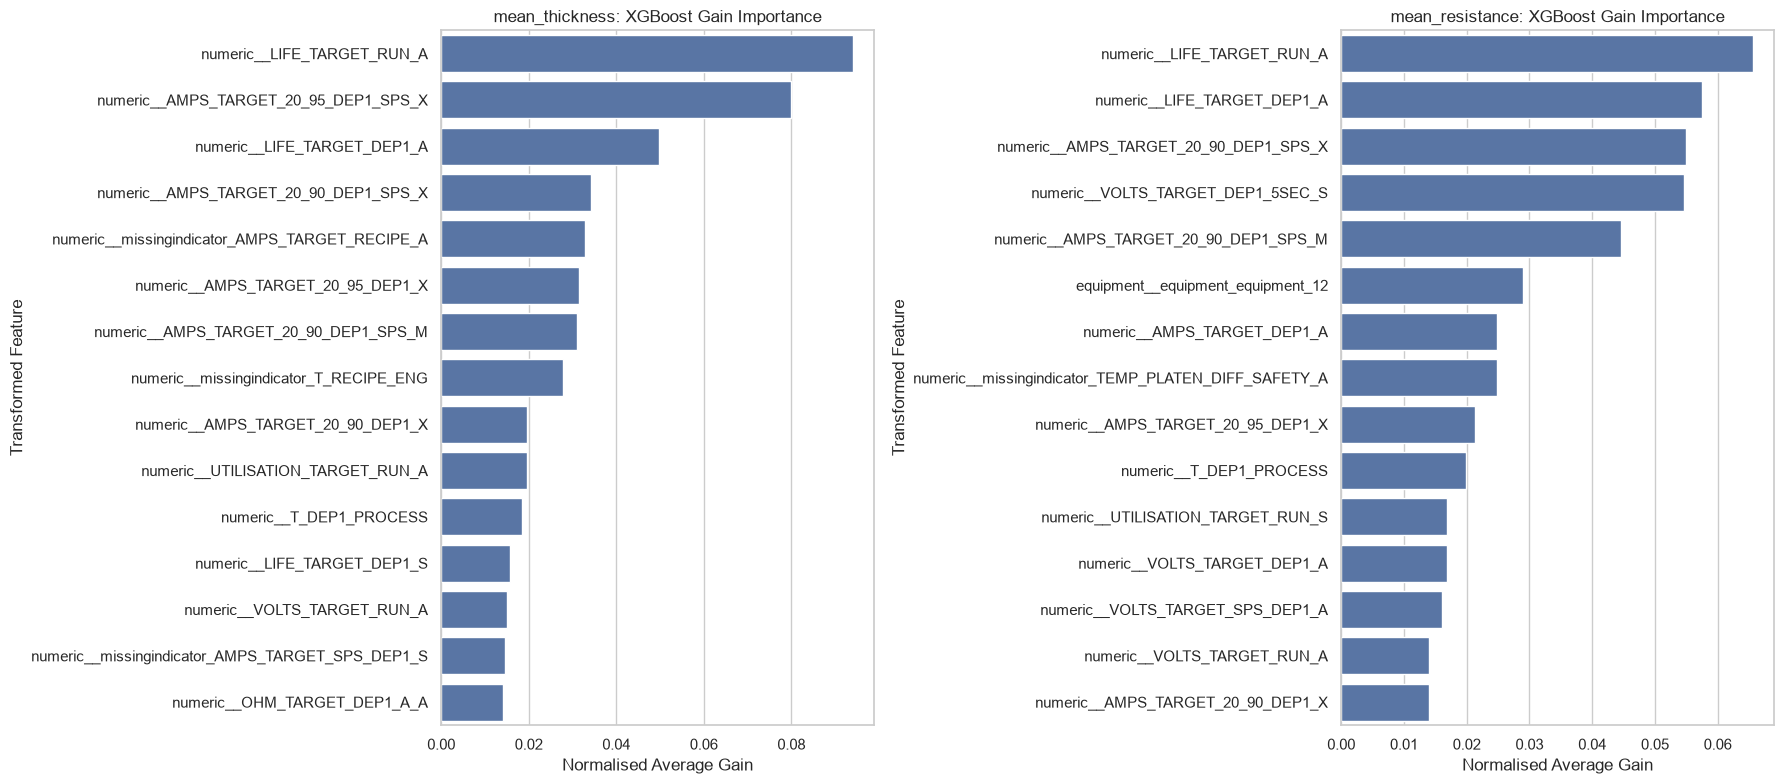

In [7]:

# Visualise gain importance

fig, axes = plt.subplots(
    1,

    2,

    figsize=(18, 8),
)

for ax, target in zip(
    axes,

    TARGETS,
):

    plot_data = (
        gain_importance[target]
        .head(TOP_N_FEATURES)
        .copy()
    )

    sns.barplot(
        data=plot_data,

        x="Gain Importance",

        y="Feature",

        ax=ax,
    )

    ax.set_title(
        f"{target}: XGBoost Gain Importance"
    )

    ax.set_xlabel(
        "Normalised Average Gain"
    )

    ax.set_ylabel("Transformed Feature")

plt.tight_layout()
plt.show()

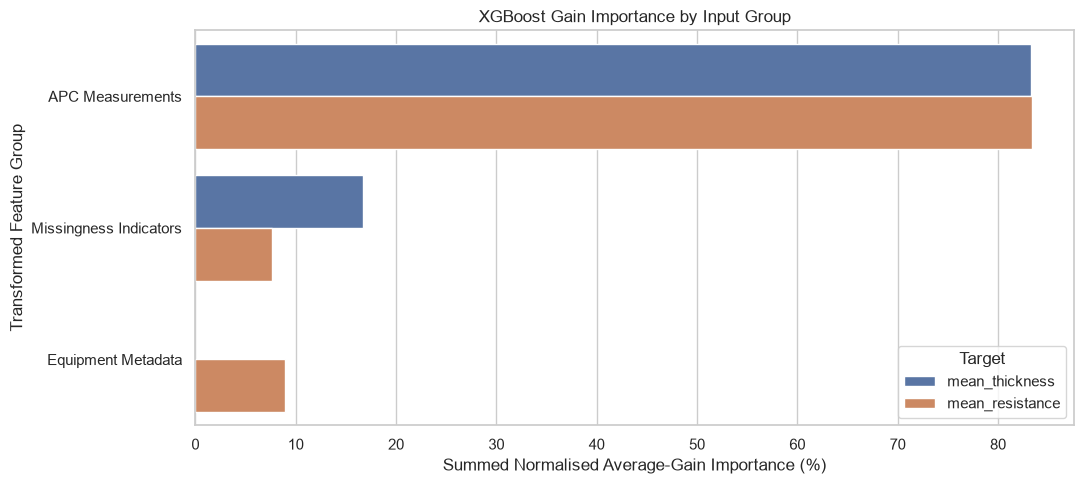

In [8]:

# Compare gain importance by feature group

plt.figure(figsize=(11, 5))

sns.barplot(
    data=gain_group_summary,

    x="Importance (%)",

    y="Group",

    hue="Target",
)

plt.title(
    "XGBoost Gain Importance by Input Group"
)

plt.xlabel(
    "Summed Normalised Average-Gain Importance (%)"
)

plt.ylabel("Transformed Feature Group")

plt.tight_layout()
plt.show()

## 5. Raw-Input Permutation Importance

Evaluate repeated permutation importance
using the original validation observations.

Permute one raw input at a time and evaluate
the increase in mean absolute prediction error.

Use five independent permutation repetitions
per feature.

Retain negative importance estimates.

Correlated predictors can substitute for
one another, and permutation may generate
unrealistic combinations of process inputs.

The results describe validation-stage
predictive reliance rather than causality.

In [9]:

# Calculate repeated permutation importance

permutation_results = {}

permutation_rows = []

for target in TARGETS:

    model = models[target]

    columns = input_columns[target]

    X_val = val_df[columns]

    y_val = val_df[target]

    baseline_mae = float(
        reproduction_summary.loc[
            reproduction_summary["Target"]
            == target,

            "MAE",
        ].iloc[0]
    )

    print(
        f"Calculating permutation importance: "
        f"{target}",

        flush=True,
    )

    start = time.perf_counter()

    result = permutation_importance(
        model,

        X_val,

        y_val,

        scoring="neg_mean_absolute_error",

        n_repeats=PERMUTATION_REPEATS,

        random_state=RANDOM_STATE,

        n_jobs=PERMUTATION_N_JOBS,
    )

    elapsed = (
        time.perf_counter() - start
    )

    importance = pd.DataFrame({
        "Feature": columns,

        "Mean MAE Increase": (
            result.importances_mean
        ),

        "Std MAE Increase": (
            result.importances_std
        ),
    })

    importance[
        "Relative MAE Increase (%)"
    ] = (
        importance["Mean MAE Increase"]
        / baseline_mae
        * 100
    )

    importance = (
        importance
        .sort_values(
            "Mean MAE Increase",
            ascending=False,
        )
        .reset_index(drop=True)
    )

    permutation_results[target] = (
        importance
    )

    permutation_rows.append({
        "Target": target,

        "Records": len(X_val),

        "Raw Features": len(columns),

        "Repeats": PERMUTATION_REPEATS,

        "Baseline MAE": baseline_mae,

        "Positive Importance Features": int(
            (
                importance["Mean MAE Increase"]
                > 0
            ).sum()
        ),

        "Negative Importance Features": int(
            (
                importance["Mean MAE Increase"]
                < 0
            ).sum()
        ),

        "Zero Importance Features": int(
            (
                importance["Mean MAE Increase"]
                == 0
            ).sum()
        ),

        "Elapsed Seconds": elapsed,
    })

    print(
        f"Completed in {elapsed:.2f} seconds."
    )

    display(
        importance.head(15)
        .round(10)
    )

permutation_summary = pd.DataFrame(
    permutation_rows
)

display(permutation_summary)

Calculating permutation importance: mean_thickness
Completed in 7.36 seconds.


,Feature,Mean MAE Increase,Std MAE Increase,Relative MAE Increase (%)
0,T_DEP1_PROCESS,0.960905,0.017381,89.590677
1,T_RECIPE_ENG,0.499910,0.016901,46.609537
2,LIFE_TARGET_DEP1_A,0.178413,0.010919,16.634449
3,LIFE_TARGET_DEP1_S,0.153081,0.012189,14.272621
4,VOLTS_TARGET_RUN_A,0.110411,0.007681,10.294284
5,LIFE_TARGET_RUN_A,0.072891,0.005766,6.796067
6,VOLTS_TARGET_RE_A,0.045285,0.005554,4.222217
7,AMPS_TARGET_20_90_DEP1_X,0.044160,0.005674,4.117248
8,FLOW_CHAMBER_RUN_A,0.040391,0.003411,3.765848
9,DCBIAS_PLATEN_DEP1_A,0.030781,0.004729,2.869875


Calculating permutation importance: mean_resistance
Completed in 10.62 seconds.


,Feature,Mean MAE Increase,Std MAE Increase,Relative MAE Increase (%)
0,T_DEP1_PROCESS,1.634620e-05,3.217000e-07,72.125711
1,T_RECIPE_ENG,9.578100e-06,3.801000e-07,42.262244
2,LIFE_TARGET_DEP1_S,2.763300e-06,2.351000e-07,12.192805
3,LIFE_TARGET_DEP1_A,2.737500e-06,2.036000e-07,12.078759
4,VOLTS_TARGET_SPS_DEP1_A,1.348100e-06,8.000000e-08,5.948198
5,VOLTS_TARGET_RUN_A,1.296500e-06,1.304000e-07,5.720454
6,AMPS_TARGET_20_90_DEP1_X,1.088600e-06,1.049000e-07,4.803497
7,VOLTS_TARGET_RE_A,1.026200e-06,1.240000e-07,4.527813
8,LIFE_TARGET_RUN_A,9.902000e-07,1.286000e-07,4.369155
9,equipment,9.598000e-07,1.013000e-07,4.235143


,Target,Records,Raw Features,Repeats,Baseline MAE,Positive Importance Features,Negative Importance Features,Zero Importance Features,Elapsed Seconds
0,mean_thickness,834,110,5,1.072550,77,28,5,7.359695
1,mean_resistance,834,111,5,0.000023,82,24,5,10.619622


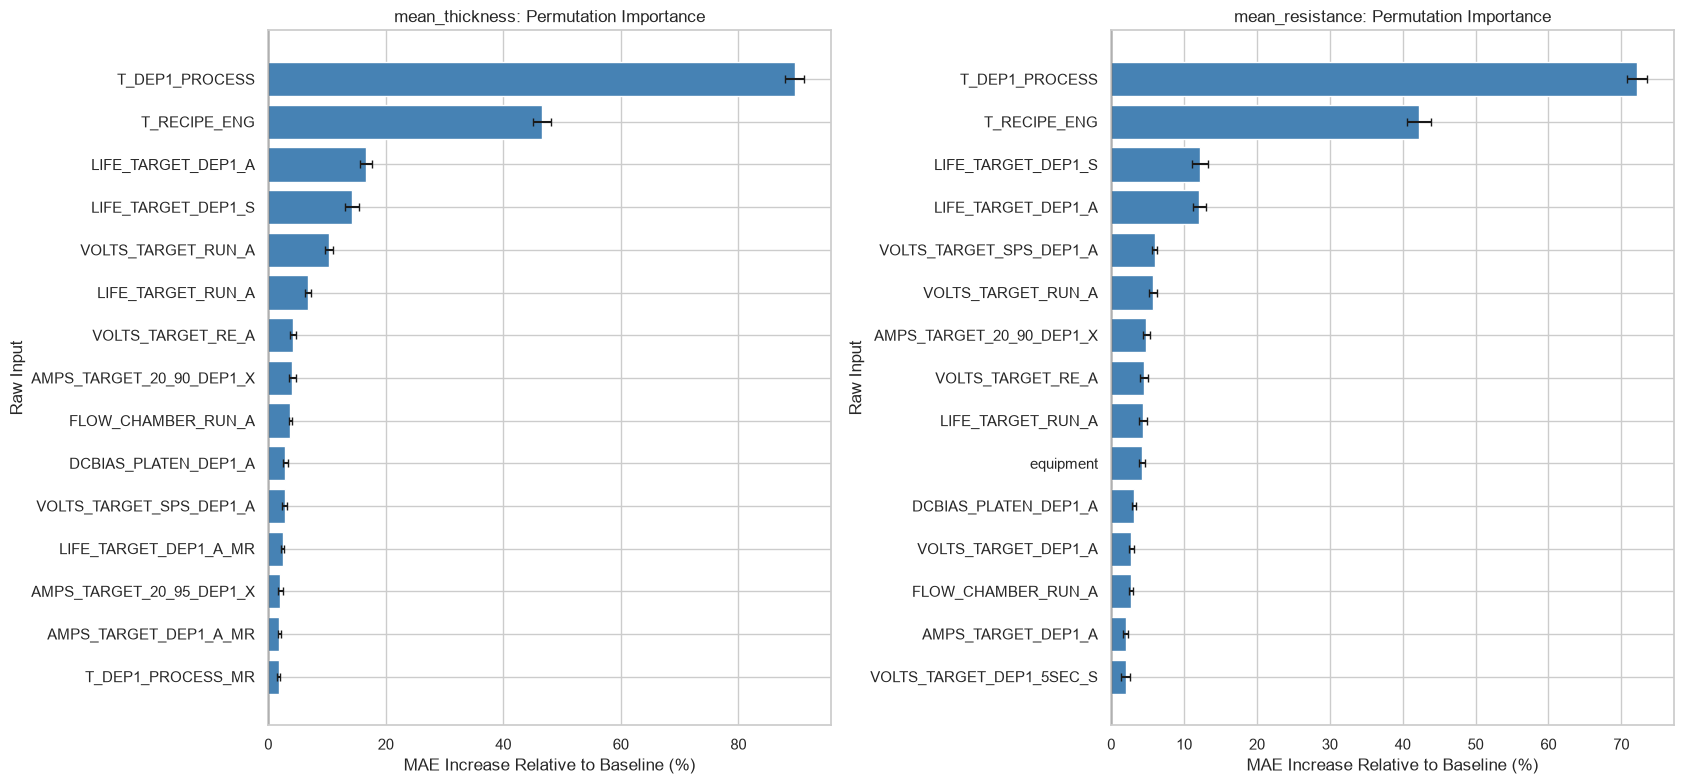

In [10]:

# Plot repeated permutation importance

fig, axes = plt.subplots(
    1,

    2,

    figsize=(17, 8),
)

for ax, target in zip(
    axes,

    TARGETS,
):

    plot_data = (
        permutation_results[target]
        .head(TOP_N_FEATURES)
        .copy()
    )

    baseline_mae = float(
        permutation_summary.loc[
            permutation_summary["Target"]
            == target,

            "Baseline MAE",
        ].iloc[0]
    )

    relative_std = (
        plot_data["Std MAE Increase"]
        / baseline_mae
        * 100
    )

    ax.barh(
        plot_data["Feature"],

        plot_data[
            "Relative MAE Increase (%)"
        ],

        xerr=relative_std,

        capsize=3,

        color="steelblue",
    )

    ax.axvline(
        0,

        color="black",

        linewidth=1,
    )

    ax.invert_yaxis()

    ax.set_title(
        f"{target}: Permutation Importance"
    )

    ax.set_xlabel(
        "MAE Increase Relative to Baseline (%)"
    )

    ax.set_ylabel("Raw Input")

plt.tight_layout()
plt.show()

## 6. Native XGBoost TreeSHAP Contributions

Calculate exact native TreeSHAP contributions
using the fitted XGBoost boosters.

Use transformed validation inputs.

Convert resistance contributions and base
predictions into the original target scale.

Verify that each additive explanation
reconstructs the complete pipeline prediction.

Aggregate transformed contributions according
to their originating raw input.

In [11]:
# Diagnose TreeSHAP numerical reconstruction

import xgboost as xgb

for target in TARGETS:

    model = models[target]

    pipeline, target_mean, target_scale = (
        unwrap_fitted_pipeline(model)
    )

    transformed = (
        pipeline.named_steps["preprocessor"]
        .transform(val_df[input_columns[target]])
    )

    booster = (
        pipeline.named_steps["regressor"]
        .get_booster()
    )

    matrix = xgb.DMatrix(
        transformed,
        feature_names=booster.feature_names,
    )

    contributions = booster.predict(
        matrix,
        pred_contribs=True,
        approx_contribs=False,
    ).astype(np.float64)

    reconstructed = (
        contributions.sum(axis=1)
        * target_scale
        + target_mean
    )

    booster_predictions = (
        booster.predict(
            matrix,
            output_margin=True,
        ).astype(np.float64)
        * target_scale
        + target_mean
    )

    actual_predictions = np.asarray(
        model.predict(
            val_df[input_columns[target]]
        ),
        dtype=np.float64,
    )

    errors = np.abs(
        reconstructed - actual_predictions
    )

    relative_errors = (
        errors / np.abs(actual_predictions)
    )

    print("\nTarget:", target)

    print("Boosting rounds:",
          booster.num_boosted_rounds())

    print("Maximum reconstruction error:",
          errors.max())

    print("Mean reconstruction error:",
          errors.mean())

    print("Maximum relative error:",
          relative_errors.max())

    print("Maximum relative error (%):",
          relative_errors.max() * 100)

    print("Booster vs pipeline maximum difference:",
          np.max(np.abs(
              booster_predictions - actual_predictions
          )))

    print("Failures under original tolerance:",
          int((~np.isclose(
              reconstructed,
              actual_predictions,
              rtol=1e-6,
              atol=1e-10,
          )).sum()))

    print("Passes proposed tolerance:",
          np.allclose(
              reconstructed,
              actual_predictions,
              rtol=1e-5,
              atol=1e-10,
          ))


Target: mean_thickness
Boosting rounds: 820
Maximum reconstruction error: 0.0003400684872758575
Mean reconstruction error: 0.00010104500267200981
Maximum relative error: 2.275675086584391e-06
Maximum relative error (%): 0.0002275675086584391
Booster vs pipeline maximum difference: 0.0
Failures under original tolerance: 194
Passes proposed tolerance: True

Target: mean_resistance
Boosting rounds: 837
Maximum reconstruction error: 2.6868589081061045e-10
Mean reconstruction error: 1.0677740670754549e-10
Maximum relative error: 9.336154030920447e-08
Maximum relative error (%): 9.336154030920446e-06
Booster vs pipeline maximum difference: 2.2208910405163707e-10
Failures under original tolerance: 0
Passes proposed tolerance: True


In [12]:

# Calculate TreeSHAP contributions

tree_explanations = {}

raw_contribution_frames = {}

additivity_rows = []

for target in TARGETS:

    columns = input_columns[target]

    print(
        "Calculating TreeSHAP:",

        target,

        flush=True,
    )

    start = time.perf_counter()

    explanation = (
        calculate_tree_contributions(
            models[target],

            val_df[columns],
        )
    )

    elapsed = (
        time.perf_counter() - start
    )

    grouped = (
        aggregate_raw_contributions(
            explanation,

            apc_features,
        )
    )

    assert len(grouped) == len(val_df)

    assert set(
        grouped.columns
    ) == set(columns)

    np.testing.assert_allclose(
        explanation["predictions"],

        predictions[target],

        rtol=1e-6,

        atol=1e-10,
    )

    tree_explanations[target] = (
        explanation
    )

    raw_contribution_frames[target] = (
        grouped
    )

    additivity_rows.append({
        "Target": target,

        "Records": len(grouped),

        "Transformed Features": len(
            explanation["feature_names"]
        ),

        "Raw Input Groups": (
            grouped.shape[1]
        ),

        "Mean Base Prediction": float(
            explanation[
                "base_predictions"
            ].mean()
        ),

        "Target Mean": (
            explanation["target_mean"]
        ),

        "Target Scale": (
            explanation["target_scale"]
        ),

        "Maximum Reconstruction Error": (
            explanation[
                "maximum_reconstruction_error"
            ]
        ),

        "Mean Reconstruction Error": (
            explanation[
                "mean_reconstruction_error"
            ]
        ),

        "Elapsed Seconds": elapsed,
    })

    print(
        f"{target}: Additivity verified."
    )

additivity_summary = pd.DataFrame(
    additivity_rows
)

display(additivity_summary)

print(
    "\nAll TreeSHAP additivity checks: PASSED"
)

Calculating TreeSHAP: mean_thickness
mean_thickness: Additivity verified.
Calculating TreeSHAP: mean_resistance
mean_resistance: Additivity verified.


,Target,Records,Transformed Features,Raw Input Groups,Mean Base Prediction,Target Mean,Target Scale,Maximum Reconstruction Error,Mean Reconstruction Error,Elapsed Seconds
0,mean_thickness,834,157,110,152.334000,0.000000,1.000000,3.400685e-04,1.010450e-04,0.179416
1,mean_resistance,834,173,111,0.002895,0.002894,0.000053,2.686859e-10,1.067774e-10,0.190171



All TreeSHAP additivity checks: PASSED


In [13]:
# Verify original-scale resistance contributions

res_explanation = tree_explanations[
    "mean_resistance"
]

res_model = models["mean_resistance"]

np.testing.assert_allclose(
    res_explanation["target_mean"],
    assessment_train_df["mean_resistance"].mean(),
    rtol=1e-12,
)

np.testing.assert_allclose(
    res_explanation["target_scale"],
    assessment_train_df["mean_resistance"].std(ddof=0),
    rtol=1e-12,
)

res_check = pd.DataFrame({
    "Base Prediction": (
        res_explanation["base_predictions"]
    ),

    "Total Contribution": (
        res_explanation["contributions"].sum(axis=1)
    ),

    "Reconstructed": (
        res_explanation["reconstructed_predictions"]
    ),

    "Pipeline Prediction": (
        res_explanation["predictions"]
    ),
})

res_check["Absolute Difference"] = np.abs(
    res_check["Reconstructed"]
    - res_check["Pipeline Prediction"]
)

display(res_check.head(10).round(12))

print("Resistance contribution conversion: VERIFIED")

,Base Prediction,Total Contribution,Reconstructed,Pipeline Prediction,Absolute Difference
0,0.002895,-4.036949e-05,0.002854,0.002854,2.300000e-11
1,0.002895,8.409192e-05,0.002979,0.002979,4.500000e-11
2,0.002895,4.792101e-05,0.002942,0.002942,1.500000e-11
3,0.002895,1.052657e-05,0.002905,0.002905,8.000000e-12
4,0.002895,2.283863e-05,0.002917,0.002917,2.170000e-10
5,0.002895,-7.203730e-07,0.002894,0.002894,1.780000e-10
6,0.002895,4.873992e-05,0.002943,0.002943,2.500000e-11
7,0.002895,8.138841e-05,0.002976,0.002976,7.200000e-11
8,0.002895,3.715316e-05,0.002932,0.002932,8.000000e-11
9,0.002895,-2.229731e-05,0.002872,0.002872,1.230000e-10


Resistance contribution conversion: VERIFIED


## 7. Global TreeSHAP Importance

Calculate mean absolute feature contributions
across all original-validation observations.

Preserve both transformed-feature importance
and raw-input grouped importance.

Mean absolute contributions measure the
magnitude of model attributions.

Mean signed contributions describe the average
direction within the explanation population.

Relative importance percentages are normalised
attribution magnitudes rather than explained
variance percentages.

In [14]:
# Calculate global TreeSHAP importance

global_transformed_shap = {}

global_raw_shap = {}

for target in TARGETS:

    explanation = tree_explanations[target]

    transformed_frame = pd.DataFrame(
        explanation["contributions"],
        columns=explanation["feature_names"],
    )

    global_transformed_shap[target] = (
        global_shap_importance(
            transformed_frame
        )
    )

    global_raw_shap[target] = (
        global_shap_importance(
            raw_contribution_frames[target]
        )
    )

    assert len(
        global_raw_shap[target]
    ) == len(input_columns[target])

    np.testing.assert_allclose(
        global_raw_shap[target][
            "Relative Importance (%)"
        ].sum(),
        100.0,
        atol=1e-8,
    )

    print("\nTarget:", target)

    display(
        global_raw_shap[target]
        .head(15)
        .round(10)
    )


Target: mean_thickness


,Feature,Mean Absolute Contribution,Mean Signed Contribution,Relative Importance (%)
0,T_DEP1_PROCESS,0.709419,-0.083828,11.936413
1,T_RECIPE_ENG,0.638539,0.250954,10.743814
2,LIFE_TARGET_DEP1_A,0.305319,-0.105447,5.137178
3,LIFE_TARGET_DEP1_S,0.283739,-0.004312,4.774095
4,VOLTS_TARGET_RUN_A,0.279903,-0.096366,4.709542
5,AMPS_TARGET_20_90_DEP1_X,0.163612,-0.016011,2.752872
6,LIFE_TARGET_RUN_A,0.162510,-0.064203,2.734326
7,DCBIAS_PLATEN_DEP1_A,0.151123,-0.038621,2.542736
8,VOLTS_TARGET_RE_A,0.142486,-0.021897,2.397424
9,RGA_FUNCTION_DAY,0.140502,-0.132914,2.364032



Target: mean_resistance


,Feature,Mean Absolute Contribution,Mean Signed Contribution,Relative Importance (%)
0,T_DEP1_PROCESS,0.000013,1.084200e-06,10.596889
1,T_RECIPE_ENG,0.000012,-4.617800e-06,9.732319
2,RGA_FUNCTION_DAY,0.000006,5.963200e-06,4.787632
3,LIFE_TARGET_DEP1_A,0.000005,1.673100e-06,4.041216
4,LIFE_TARGET_DEP1_S,0.000005,2.100000e-07,4.015865
5,VOLTS_TARGET_RUN_A,0.000004,1.321300e-06,3.570138
6,AMPS_TARGET_20_90_DEP1_X,0.000004,3.360000e-07,2.928555
7,VOLTS_TARGET_RE_A,0.000004,5.549000e-07,2.837954
8,VOLTS_TARGET_SPS_DEP1_A,0.000003,4.938000e-07,2.788052
9,VOLTS_TARGET_DEP1_A,0.000003,7.314000e-07,2.299167


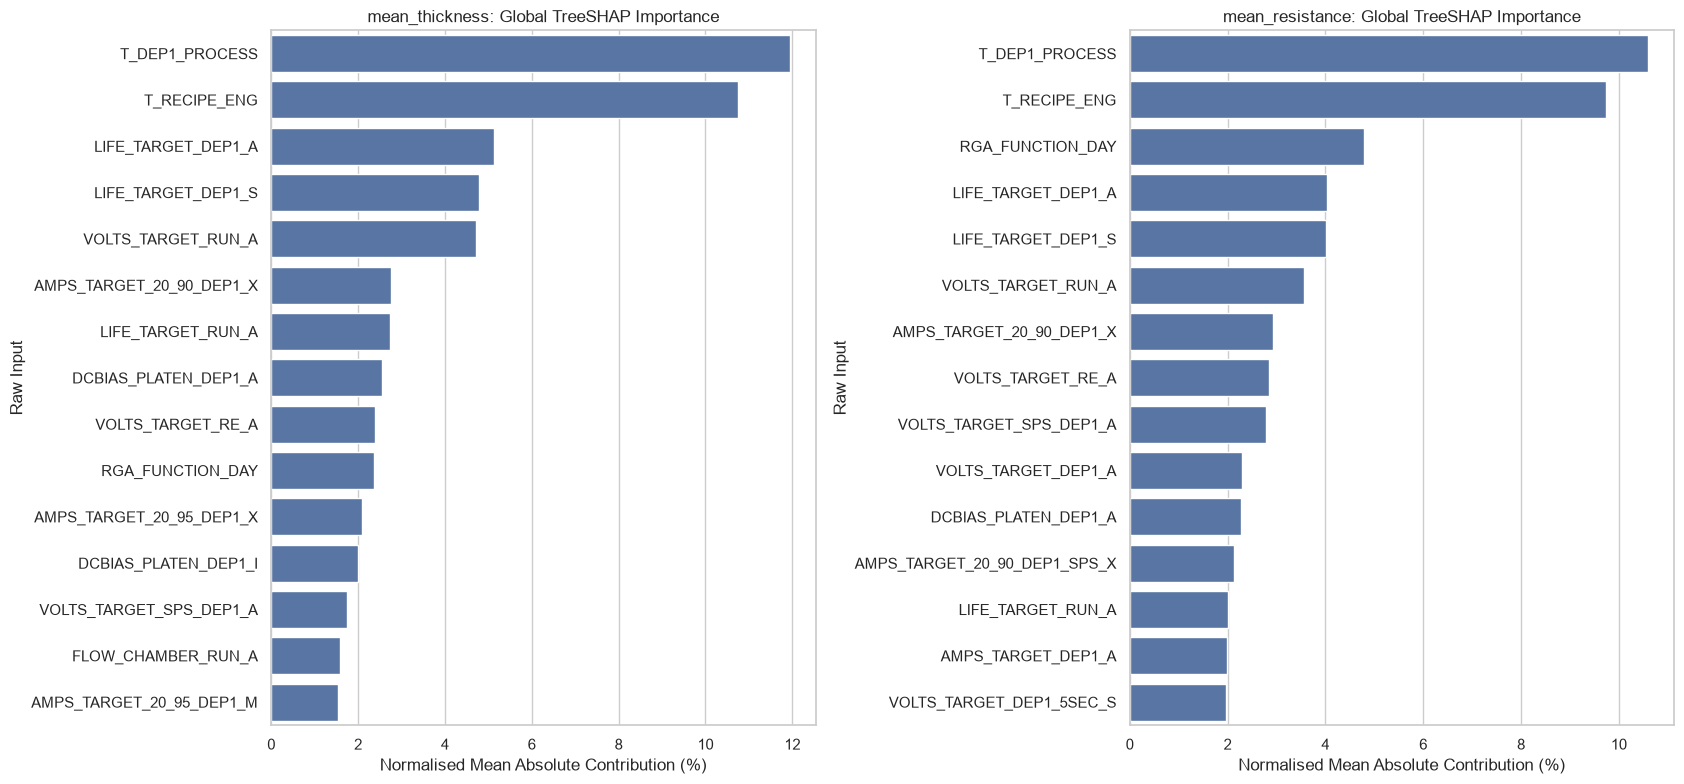

In [15]:
# Plot raw-input global SHAP importance

fig, axes = plt.subplots(
    1, 2, figsize=(17, 8)
)

for ax, target in zip(axes, TARGETS):

    plot_data = (
        global_raw_shap[target]
        .head(TOP_N_FEATURES)
        .copy()
    )

    sns.barplot(
        data=plot_data,
        x="Relative Importance (%)",
        y="Feature",
        ax=ax,
    )

    ax.set_title(
        f"{target}: Global TreeSHAP Importance"
    )

    ax.set_xlabel(
        "Normalised Mean Absolute Contribution (%)"
    )

    ax.set_ylabel("Raw Input")

plt.tight_layout()
plt.show()

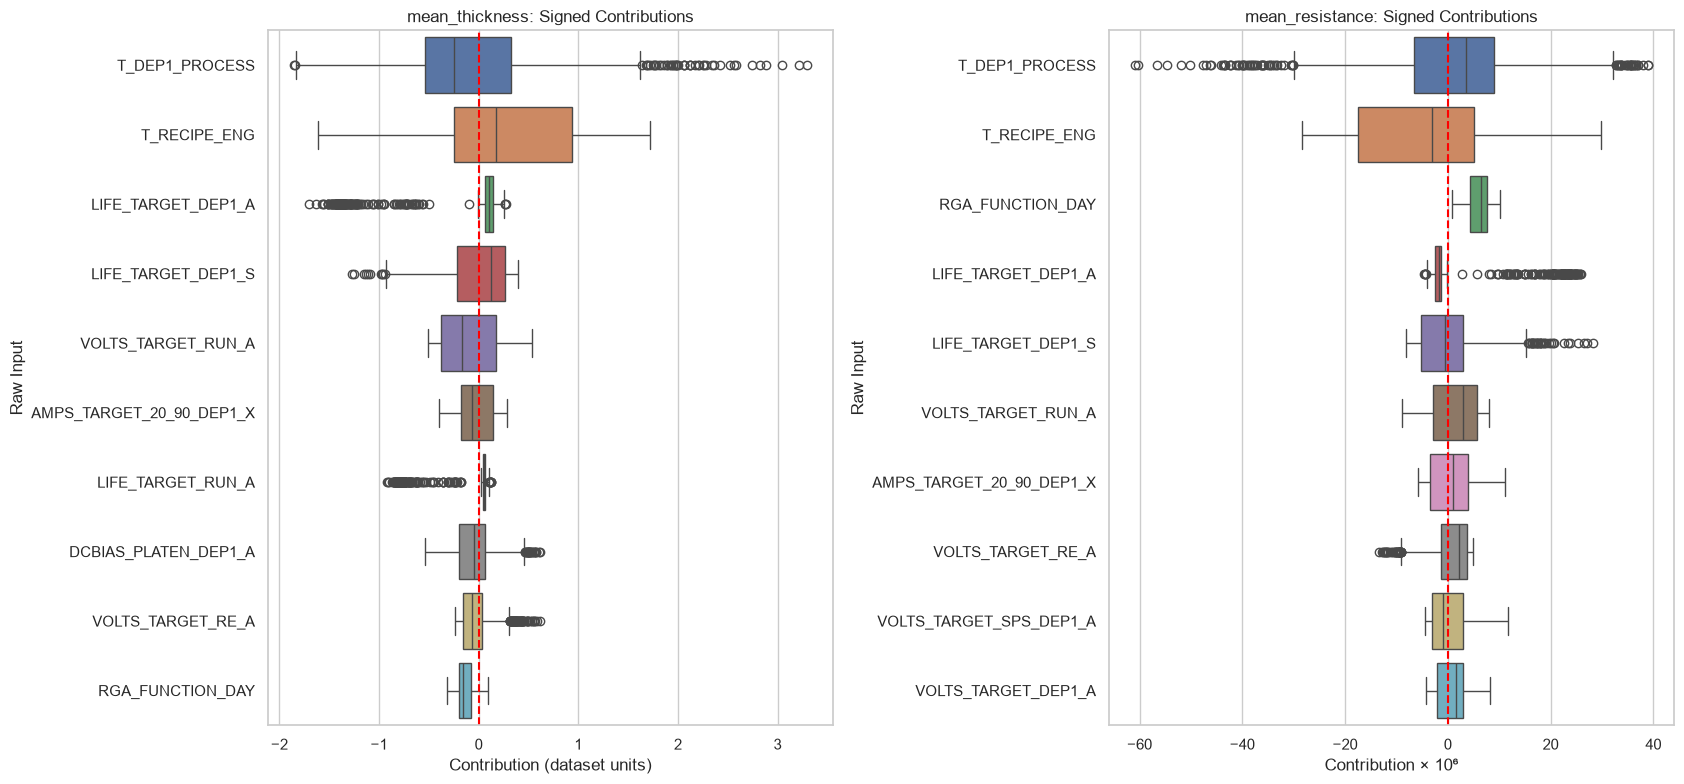

In [16]:
# Inspect signed contribution distributions

fig, axes = plt.subplots(
    1, 2, figsize=(17, 8)
)

for ax, target in zip(axes, TARGETS):

    top_features = (
        global_raw_shap[target]
        .head(10)["Feature"]
        .tolist()
    )

    display_multiplier = (
        RESISTANCE_DISPLAY_SCALE
        if target == "mean_resistance"
        else 1
    )

    plot_data = (
        raw_contribution_frames[target][top_features]
        * display_multiplier
    )

    sns.boxplot(
        data=plot_data,
        orient="h",
        ax=ax,
    )

    ax.axvline(
        0,
        color="red",
        linestyle="--",
    )

    ax.set_title(
        f"{target}: Signed Contributions"
    )

    ax.set_xlabel(
        "Contribution × 10⁶"
        if target == "mean_resistance"
        else "Contribution (dataset units)"
    )

    ax.set_ylabel("Raw Input")

plt.tight_layout()
plt.show()

## 8. Explainability Method Comparison

Compare:

- Raw-input aggregated gain importance.
- Raw-input permutation importance.
- Raw-input aggregated TreeSHAP importance.

Investigate ranking agreement through
Spearman rank correlation and top-feature overlap.

The methods capture distinct aspects of
model behaviour and need not agree.

Post-hoc aggregation is not equivalent to
recomputing Shapley values over raw groups.

In [17]:
# Compare importance rankings

method_comparisons = {}

method_agreement_rows = []

method_pairs = [
    ("Gain", "Permutation"),
    ("Gain", "SHAP"),
    ("Permutation", "SHAP"),
]

for target in TARGETS:

    raw_gain = (
        gain_importance[target]
        .groupby(
            "Raw Feature",
            as_index=False,
        )["Gain Importance"]
        .sum()
        .rename(columns={
            "Raw Feature": "Feature",
            "Gain Importance": "Gain",
        })
    )

    raw_permutation = (
        permutation_results[target][
            ["Feature", "Mean MAE Increase"]
        ]
        .rename(columns={
            "Mean MAE Increase": "Permutation",
        })
    )

    raw_shap = (
        global_raw_shap[target][
            ["Feature", "Mean Absolute Contribution"]
        ]
        .rename(columns={
            "Mean Absolute Contribution": "SHAP",
        })
    )

    combined = (
        raw_gain
        .merge(
            raw_permutation,
            on="Feature",
            validate="one_to_one",
        )
        .merge(
            raw_shap,
            on="Feature",
            validate="one_to_one",
        )
    )

    assert len(combined) == len(
        input_columns[target]
    )

    for method in ["Gain", "Permutation", "SHAP"]:

        combined[f"{method} Rank"] = (
            combined[method].rank(
                ascending=False,
                method="average",
            )
        )

    method_comparisons[target] = combined

    for first, second in method_pairs:

        rho = spearmanr(
            combined[first],
            combined[second],
        ).statistic

        first_top = set(
            combined
            .sort_values(
                [first, "Feature"],
                ascending=[False, True],
            )
            .head(10)["Feature"]
        )

        second_top = set(
            combined
            .sort_values(
                [second, "Feature"],
                ascending=[False, True],
            )
            .head(10)["Feature"]
        )

        overlap = first_top & second_top

        method_agreement_rows.append({
            "Target": target,

            "Method 1": first,

            "Method 2": second,

            "Spearman Rank Correlation": float(rho),

            "Top 10 Overlap": len(overlap),

            "Shared Features": sorted(overlap),
        })

method_agreement = pd.DataFrame(
    method_agreement_rows
)

display(method_agreement)

,Target,Method 1,Method 2,Spearman Rank Correlation,Top 10 Overlap,Shared Features
0,mean_thickness,Gain,Permutation,0.481825,4,"[AMPS_TARGET_20_90_DEP1_X, LIFE_TARGET_DEP1_A,..."
1,mean_thickness,Gain,SHAP,0.685574,4,"[AMPS_TARGET_20_90_DEP1_X, LIFE_TARGET_DEP1_A,..."
2,mean_thickness,Permutation,SHAP,0.687637,9,"[AMPS_TARGET_20_90_DEP1_X, DCBIAS_PLATEN_DEP1_..."
3,mean_resistance,Gain,Permutation,0.614955,4,"[LIFE_TARGET_DEP1_A, LIFE_TARGET_RUN_A, T_DEP1..."
4,mean_resistance,Gain,SHAP,0.759327,2,"[LIFE_TARGET_DEP1_A, T_DEP1_PROCESS]"
5,mean_resistance,Permutation,SHAP,0.694828,8,"[AMPS_TARGET_20_90_DEP1_X, LIFE_TARGET_DEP1_A,..."


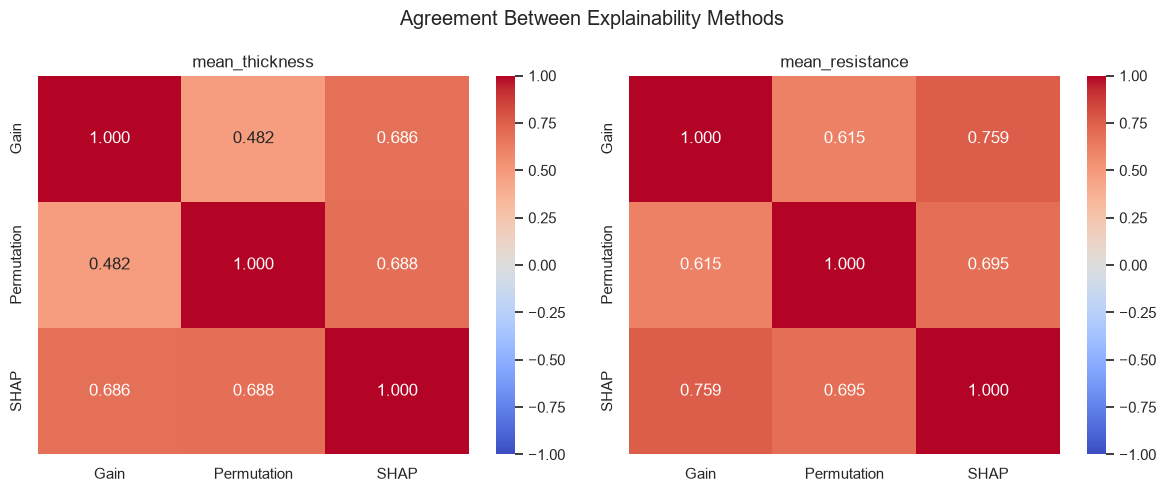

In [18]:
# Visualise method ranking agreement

fig, axes = plt.subplots(
    1, 2, figsize=(12, 5)
)

for ax, target in zip(axes, TARGETS):

    correlation_matrix = (
        method_comparisons[target][
            ["Gain", "Permutation", "SHAP"]
        ]
        .corr(method="spearman")
    )

    sns.heatmap(
        correlation_matrix,
        annot=True,
        fmt=".3f",
        cmap="coolwarm",
        vmin=-1,
        vmax=1,
        ax=ax,
    )

    ax.set_title(target)

plt.suptitle(
    "Agreement Between Explainability Methods"
)

plt.tight_layout()
plt.show()

## 9. Cross-Target Predictor Comparison

Compare global TreeSHAP importance across
the thickness and resistance models.

Restrict rank comparison to shared APC inputs.

Retain equipment metadata separately because
it is not an input to the frozen thickness model.

Investigate top-feature overlap and
target-specific predictor reliance.

The comparison concerns model attributions,
not shared physical causal mechanisms.

In [19]:
# Compare global SHAP importance across targets

thickness_shap = (
    global_raw_shap["mean_thickness"][
        ["Feature", "Relative Importance (%)"]
    ]
    .rename(columns={
        "Relative Importance (%)":
            "Thickness Importance (%)",
    })
)

resistance_shap = (
    global_raw_shap["mean_resistance"][
        ["Feature", "Relative Importance (%)"]
    ]
    .rename(columns={
        "Relative Importance (%)":
            "Resistance Importance (%)",
    })
)

cross_target_importance = (
    thickness_shap.merge(
        resistance_shap,
        on="Feature",
        how="inner",
        validate="one_to_one",
    )
)

assert len(cross_target_importance) == 110

assert set(
    cross_target_importance["Feature"]
) == set(apc_features)

cross_target_rho = float(
    spearmanr(
        cross_target_importance[
            "Thickness Importance (%)"
        ],
        cross_target_importance[
            "Resistance Importance (%)"
        ],
    ).statistic
)

thickness_top_10 = set(
    thickness_shap.head(10)["Feature"]
)

resistance_apc_top_10 = set(
    resistance_shap.loc[
        resistance_shap["Feature"] != "equipment"
    ]
    .head(10)["Feature"]
)

shared_top_features = sorted(
    thickness_top_10 & resistance_apc_top_10
)

print(
    "Cross-target APC rank correlation:",
    cross_target_rho,
)

print(
    "Shared top-10 APC predictors:",
    len(shared_top_features),
)

print(shared_top_features)

display(
    cross_target_importance.loc[
        cross_target_importance["Feature"]
        .isin(shared_top_features)
    ].round(6)
)

Cross-target APC rank correlation: 0.8501807820967117
Shared top-10 APC predictors: 8
['AMPS_TARGET_20_90_DEP1_X', 'LIFE_TARGET_DEP1_A', 'LIFE_TARGET_DEP1_S', 'RGA_FUNCTION_DAY', 'T_DEP1_PROCESS', 'T_RECIPE_ENG', 'VOLTS_TARGET_RE_A', 'VOLTS_TARGET_RUN_A']


,Feature,Thickness Importance (%),Resistance Importance (%)
0,T_DEP1_PROCESS,11.936413,10.596889
1,T_RECIPE_ENG,10.743814,9.732319
2,LIFE_TARGET_DEP1_A,5.137178,4.041216
3,LIFE_TARGET_DEP1_S,4.774095,4.015865
4,VOLTS_TARGET_RUN_A,4.709542,3.570138
5,AMPS_TARGET_20_90_DEP1_X,2.752872,2.928555
8,VOLTS_TARGET_RE_A,2.397424,2.837954
9,RGA_FUNCTION_DAY,2.364032,4.787632


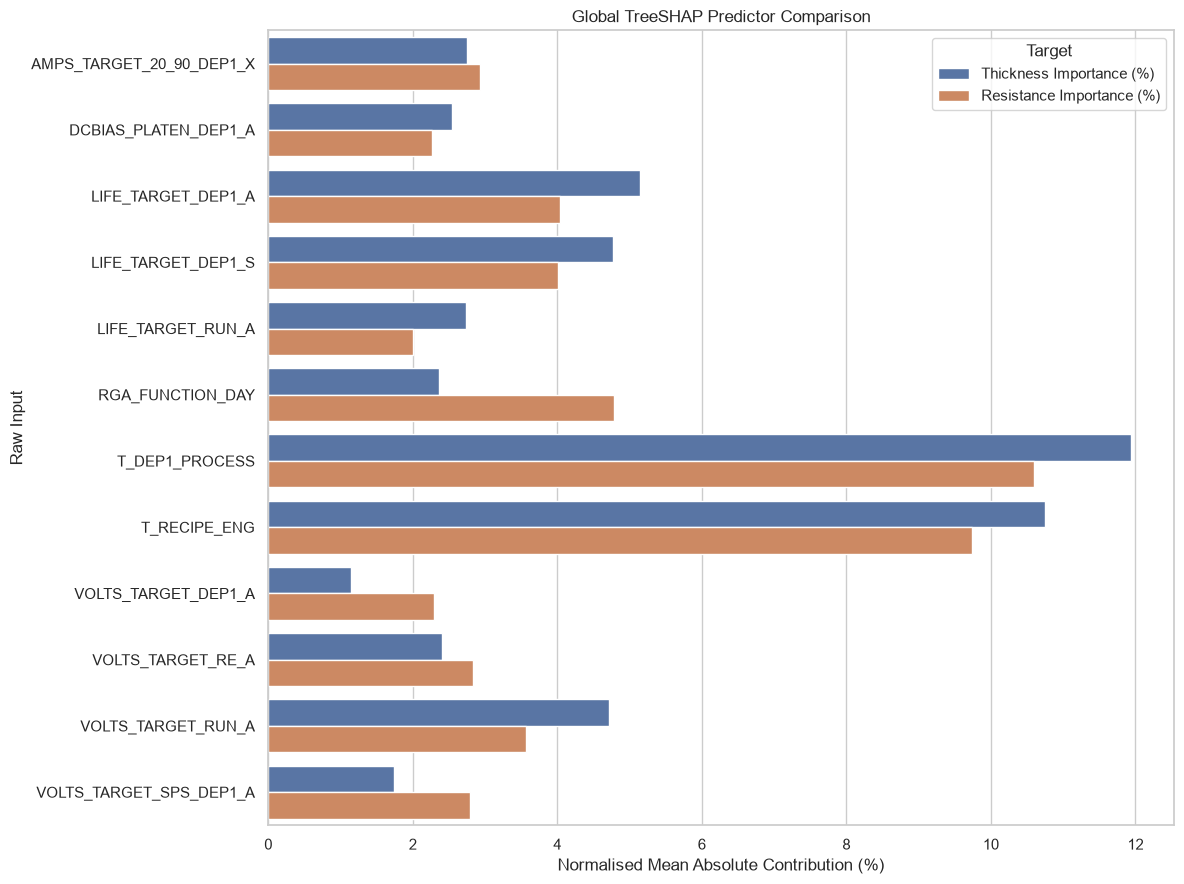

In [20]:
# Visualise shared and target-specific predictors

plot_features = list(
    dict.fromkeys(
        thickness_shap.head(10)["Feature"].tolist()
        +
        resistance_shap.head(10)["Feature"].tolist()
    )
)

comparison_plot_data = thickness_shap.merge(
    resistance_shap,
    on="Feature",
    how="outer",
)

comparison_plot_data = (
    comparison_plot_data.loc[
        comparison_plot_data["Feature"]
        .isin(plot_features)
    ]
)

comparison_plot_data = (
    comparison_plot_data.melt(
        id_vars=["Feature"],

        value_vars=[
            "Thickness Importance (%)",
            "Resistance Importance (%)",
        ],

        var_name="Target",

        value_name="Relative Importance (%)",
    )
    .dropna()
)

plt.figure(figsize=(12, 9))

sns.barplot(
    data=comparison_plot_data,
    x="Relative Importance (%)",
    y="Feature",
    hue="Target",
)

plt.title(
    "Global TreeSHAP Predictor Comparison"
)

plt.xlabel(
    "Normalised Mean Absolute Contribution (%)"
)

plt.ylabel("Raw Input")

plt.tight_layout()
plt.show()

## 10. Feature Value and Contribution Relationships

Investigate the relationship between observed
APC values and their grouped TreeSHAP contributions.

Select the three leading APC predictors for
each target according to mean absolute
contribution.

Exclude missing raw values from the scatterplots.

The plots describe observational model
behaviour and may reflect feature interactions,
equipment differences, and correlated inputs.

They are not physical response curves or
process intervention experiments.

,Target,Feature,Observed Records,Missing Records
0,mean_thickness,T_DEP1_PROCESS,834,0
1,mean_thickness,T_RECIPE_ENG,834,0
2,mean_thickness,LIFE_TARGET_DEP1_A,834,0
3,mean_resistance,T_DEP1_PROCESS,834,0
4,mean_resistance,T_RECIPE_ENG,834,0
5,mean_resistance,RGA_FUNCTION_DAY,834,0


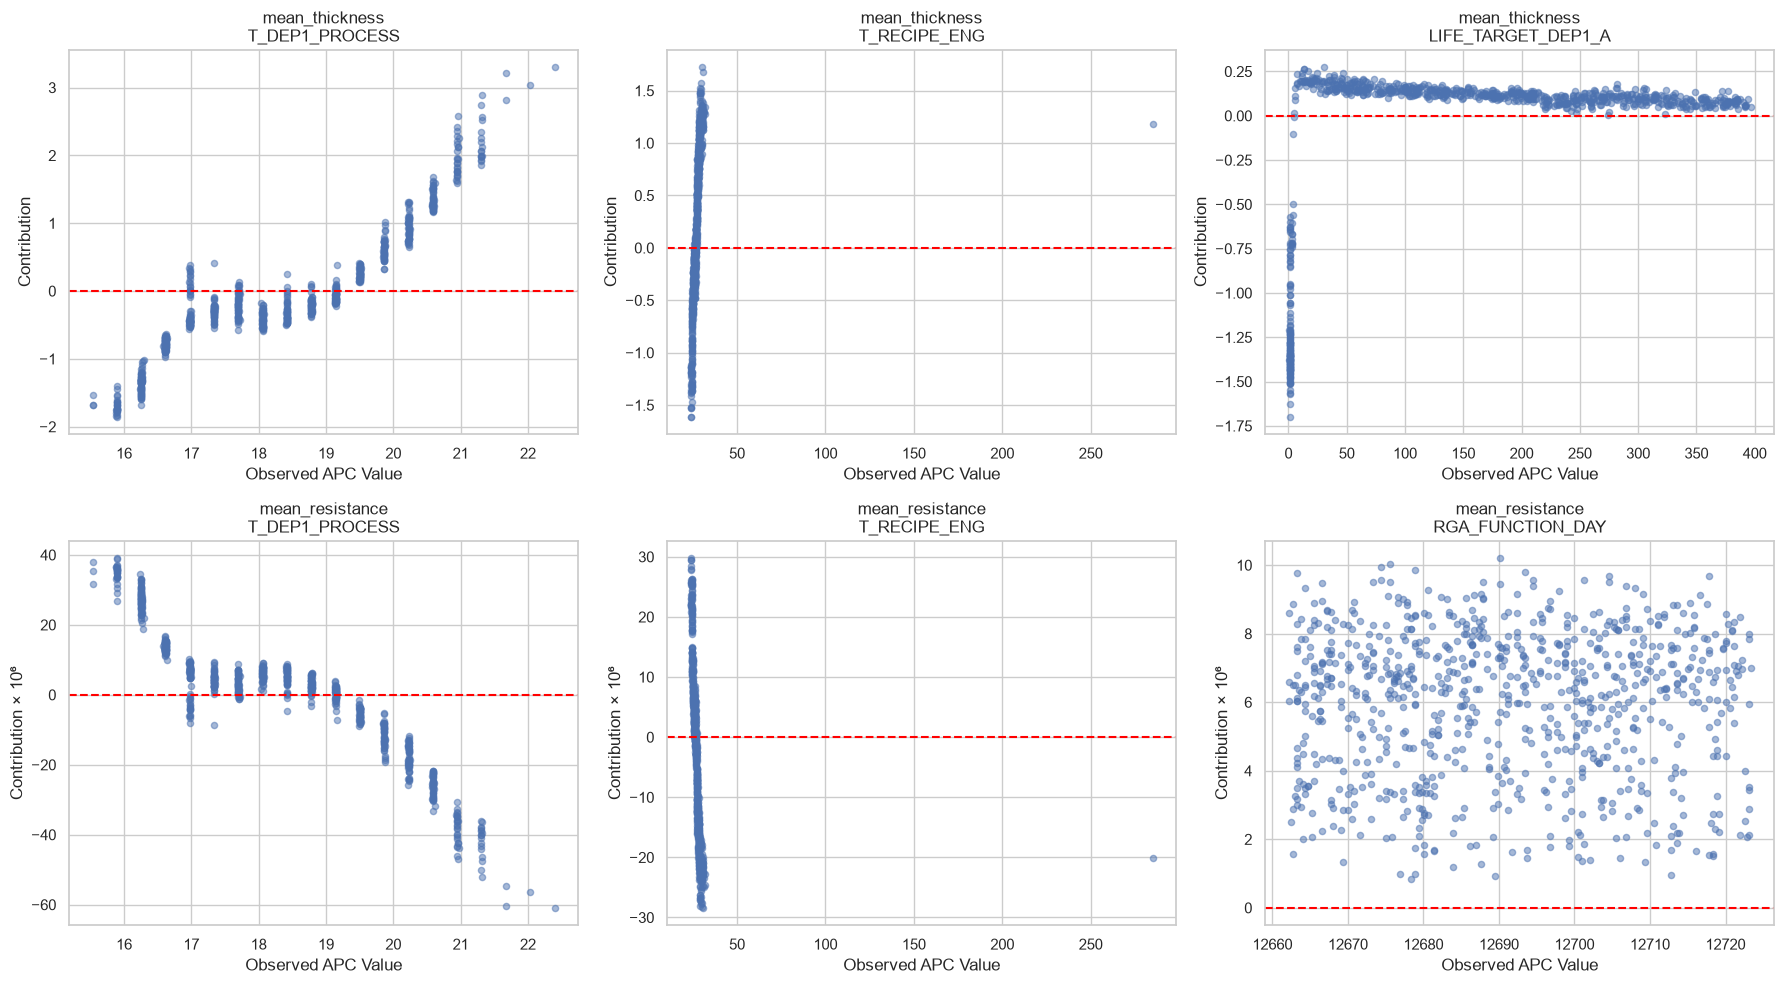

In [21]:
# Plot observed APC values against contributions

fig, axes = plt.subplots(
    2, 3, figsize=(18, 10)
)

dependence_summary_rows = []

for row, target in enumerate(TARGETS):

    top_apc_features = (
        global_raw_shap[target]
        .loc[
            global_raw_shap[target]["Feature"]
            != "equipment"
        ]
        .head(3)["Feature"]
        .tolist()
    )

    multiplier = (
        RESISTANCE_DISPLAY_SCALE
        if target == "mean_resistance"
        else 1
    )

    for column, feature in enumerate(
        top_apc_features
    ):

        ax = axes[row, column]

        x = val_df[feature].to_numpy(dtype=float)

        y = (
            raw_contribution_frames[target][feature]
            .to_numpy()
        )

        valid = (
            np.isfinite(x)
            & np.isfinite(y)
        )

        ax.scatter(
            x[valid],
            y[valid] * multiplier,
            alpha=0.5,
            s=20,
        )

        ax.axhline(
            0,
            color="red",
            linestyle="--",
        )

        ax.set_title(
            f"{target}\n{feature}"
        )

        ax.set_xlabel("Observed APC Value")

        ax.set_ylabel(
            "Contribution × 10⁶"
            if target == "mean_resistance"
            else "Contribution"
        )

        dependence_summary_rows.append({
            "Target": target,

            "Feature": feature,

            "Observed Records": int(valid.sum()),

            "Missing Records": int((~valid).sum()),
        })

dependence_summary = pd.DataFrame(
    dependence_summary_rows
)

display(dependence_summary)

plt.tight_layout()
plt.show()

## 11. Individual Wafer Explanation Case Studies

Select four original-validation diagnostic cases.

1. Observation with joint relative prediction
   error closest to the median.

2. Observation with maximum thickness
   absolute prediction error.

3. Observation with maximum resistance
   absolute prediction error.

4. First chronological observation from
   equipment_16.

Use actual metrology only for retrospective
case selection and error assessment.

Generate prediction explanations exclusively
from the corresponding process inputs.

The selected cases are illustrative rather
than a representative evaluation sample.

In [22]:
# Select individual explanation cases

case_diagnostics = pd.DataFrame({
    "wafer_id": val_df["wafer_id"].to_numpy(),

    "equipment": val_df["equipment"].to_numpy(),

    "Actual Thickness": (
        val_df["mean_thickness"].to_numpy()
    ),

    "Predicted Thickness": (
        predictions["mean_thickness"]
    ),

    "Actual Resistance": (
        val_df["mean_resistance"].to_numpy()
    ),

    "Predicted Resistance": (
        predictions["mean_resistance"]
    ),
})

case_diagnostics["Thickness Absolute Error"] = (
    np.abs(
        case_diagnostics["Actual Thickness"]
        - case_diagnostics["Predicted Thickness"]
    )
)

case_diagnostics["Resistance Absolute Error"] = (
    np.abs(
        case_diagnostics["Actual Resistance"]
        - case_diagnostics["Predicted Resistance"]
    )
)

case_diagnostics["Joint Relative Error"] = 0.5 * (
    (
        case_diagnostics["Thickness Absolute Error"]
        / case_diagnostics["Actual Thickness"]
    )
    +
    (
        case_diagnostics["Resistance Absolute Error"]
        / case_diagnostics["Actual Resistance"]
    )
)

median_joint_error = (
    case_diagnostics["Joint Relative Error"].median()
)

typical_index = int(
    (
        case_diagnostics["Joint Relative Error"]
        - median_joint_error
    )
    .abs()
    .idxmin()
)

max_thickness_index = int(
    case_diagnostics["Thickness Absolute Error"]
    .idxmax()
)

max_resistance_index = int(
    case_diagnostics["Resistance Absolute Error"]
    .idxmax()
)

equipment_16_indices = case_diagnostics.index[
    case_diagnostics["equipment"] == "equipment_16"
]

assert len(equipment_16_indices) > 0

equipment_16_index = int(equipment_16_indices[0])

case_indices = {
    "Typical Joint Error": typical_index,

    "Maximum Thickness Error": max_thickness_index,

    "Maximum Resistance Error": max_resistance_index,

    "Equipment 16 Example": equipment_16_index,
}

case_summary_rows = []

for label, index in case_indices.items():

    row = case_diagnostics.iloc[index].to_dict()

    case_summary_rows.append({
        "Case": label,

        "Validation Position": index,

        **row,
    })

case_summary = pd.DataFrame(case_summary_rows)

display(case_summary.round(10))

,Case,Validation Position,wafer_id,equipment,Actual Thickness,Predicted Thickness,Actual Resistance,Predicted Resistance,Thickness Absolute Error,Resistance Absolute Error,Joint Relative Error
0,Typical Joint Error,57,V6G01XP423,equipment_12,148.064109,148.852356,0.002986,0.002969,0.788247,0.000017,0.005564
1,Maximum Thickness Error,73,V6F02J2U19,equipment_6,145.625454,151.446716,0.003110,0.002922,5.821262,0.000188,0.050139
2,Maximum Resistance Error,724,V6G01YN905,equipment_15,151.184866,151.542587,0.003109,0.002911,0.357721,0.000198,0.033020
3,Equipment 16 Example,22,V6F02GJ707,equipment_16,150.317389,150.974701,0.002926,0.002924,0.657312,0.000002,0.002531


In [23]:
# Generate local explanation evidence

case_explanations = {}

for label, index in case_indices.items():

    case_explanations[label] = {}

    for target in TARGETS:

        columns = input_columns[target]

        record = val_df[columns].iloc[[index]]

        explanation = explain_single_prediction(
            model=models[target],

            inputs=record,

            apc_features=apc_features,

            target=target,

            top_n=10,
        )

        explanation["model_candidate"] = (
            model_configs[target]["name"]
        )

        np.testing.assert_allclose(
            explanation["prediction"],
            predictions[target][index],
            rtol=1e-6,
            atol=1e-10,
        )

        case_explanations[label][target] = explanation

        print(
            f"{label} | {target} | "
            f"Prediction: "
            f"{explanation['prediction']:.10f}"
        )

print("\nAll local explanation cases generated.")

Typical Joint Error | mean_thickness | Prediction: 148.8523559570
Typical Joint Error | mean_resistance | Prediction: 0.0029685376
Maximum Thickness Error | mean_thickness | Prediction: 151.4467163086
Maximum Thickness Error | mean_resistance | Prediction: 0.0029220304
Maximum Resistance Error | mean_thickness | Prediction: 151.5425872803
Maximum Resistance Error | mean_resistance | Prediction: 0.0029112766
Equipment 16 Example | mean_thickness | Prediction: 150.9747009277
Equipment 16 Example | mean_resistance | Prediction: 0.0029236800

All local explanation cases generated.


In [24]:
# Inspect a typical thickness explanation

example = case_explanations[
    "Typical Joint Error"
]["mean_thickness"]

print(
    "Base prediction:",
    example["base_prediction"],
)

print(
    "Final prediction:",
    example["prediction"],
)

print(
    "Reconstructed prediction:",
    example["reconstructed_prediction"],
)

print(
    "Reconstruction error:",
    example["reconstruction_error"],
)

display(
    pd.DataFrame(
        example["top_features"]
    ).round(8)
)

Base prediction: 152.33399963378906
Final prediction: 148.85235595703125
Reconstructed prediction: 148.85211864699704
Reconstruction error: 0.00023731003420834895


,feature,input_value,input_missing,contribution,absolute_contribution,direction
0,T_RECIPE_ENG,28.204457,False,0.763955,0.763955,increases_prediction
1,T_DEP1_PROCESS,18.420163,False,-0.472235,0.472235,decreases_prediction
2,VOLTS_TARGET_RUN_A,119.611380,False,-0.467761,0.467761,decreases_prediction
3,AMPS_TARGET_20_95_DELTA_DEP1,0.862196,False,-0.321760,0.321760,decreases_prediction
4,RGA_FUNCTION_DAY,12665.482984,False,-0.235447,0.235447,decreases_prediction
5,AMPS_TARGET_20_95_DEP1_X,36.709161,False,-0.210254,0.210254,decreases_prediction
6,AMPS_TARGET_20_90_DELTA_DEP1,0.894602,False,-0.196921,0.196921,decreases_prediction
7,VOLTS_TARGET_RE_A,129.932689,False,-0.195651,0.195651,decreases_prediction
8,AMPS_TARGET_20_90_DEP1_X,38.644401,False,-0.191454,0.191454,decreases_prediction
9,AMPS_TARGET_20_90_DEP1_M,16.991179,False,-0.178596,0.178596,decreases_prediction


## 12. Local Signed Contribution Visualisation

Visualise the ten largest absolute raw-input
contributions for each selected wafer case.

Use signed contributions to distinguish
features that raise or lower the prediction
relative to its model baseline.

Retain an aggregated remainder contribution
for omitted features.

All resistance contributions are expressed
in the original target scale before applying
the graphical display multiplier.

In [25]:
# Reusable local explanation plotting function

def plot_local_explanation(
    explanation,
    ax,
    title,
    multiplier=1,
):

    plot_data = pd.DataFrame(
        explanation["top_features"]
    )[
        ["feature", "contribution"]
    ].copy()

    plot_data = pd.concat(
        [
            plot_data,

            pd.DataFrame([{
                "feature": "Other Features",

                "contribution": (
                    explanation[
                        "other_feature_contribution"
                    ]
                ),
            }]),
        ],

        ignore_index=True,
    )

    plot_data["Display Contribution"] = (
        plot_data["contribution"]
        * multiplier
    )

    colors = [
        "indianred"
        if value > 0
        else "steelblue"

        for value in plot_data["Display Contribution"]
    ]

    ax.barh(
        plot_data["feature"],
        plot_data["Display Contribution"],
        color=colors,
    )

    ax.axvline(
        0,
        color="black",
        linewidth=1,
    )

    ax.invert_yaxis()

    ax.set_title(title)

    ax.set_xlabel(
        "Signed Contribution × 10⁶"
        if multiplier == 1_000_000
        else "Signed Contribution"
    )

    ax.set_ylabel("Raw Input")


print("Local explanation plotting ready.")

Local explanation plotting ready.


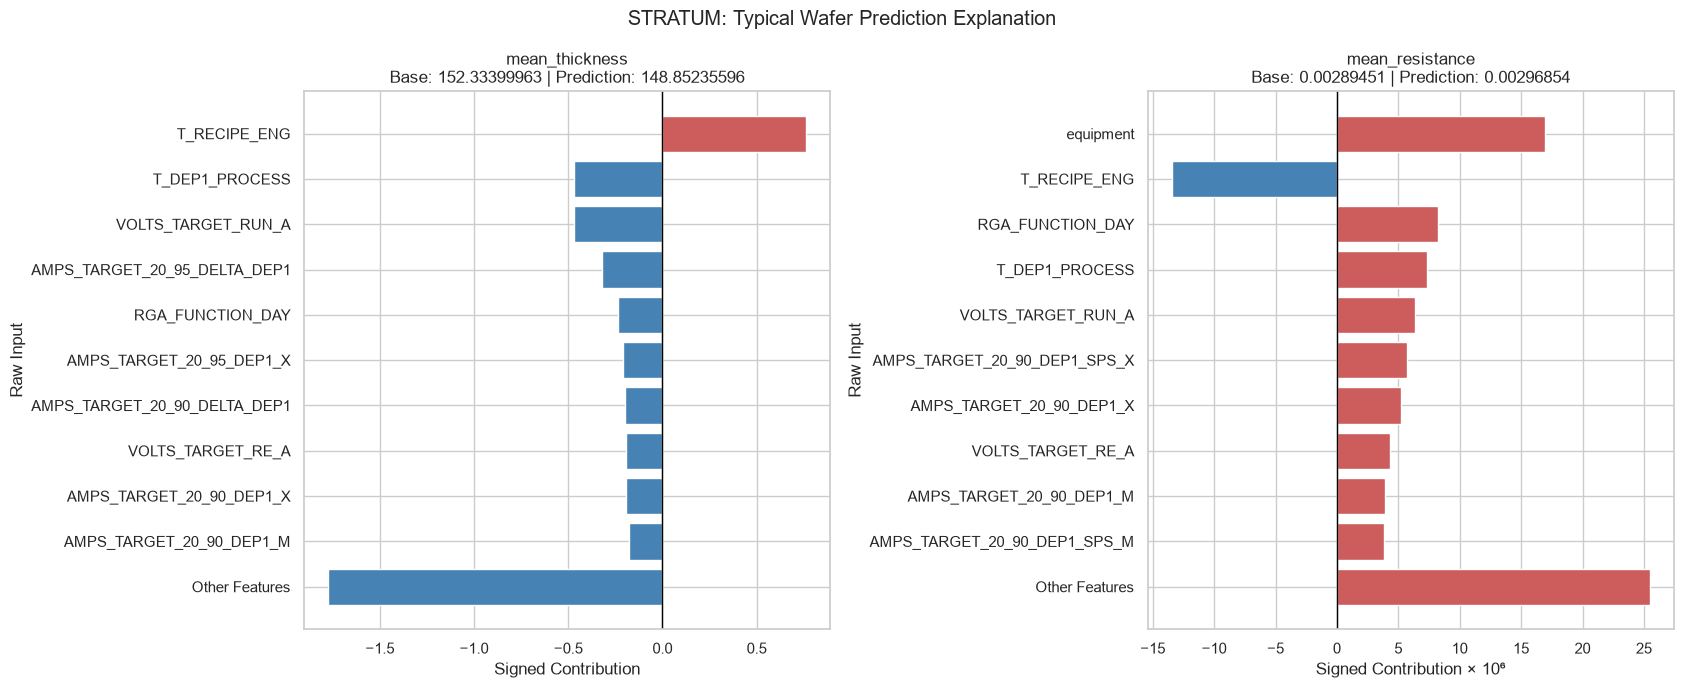

In [26]:
# Typical wafer explanation

label = "Typical Joint Error"

fig, axes = plt.subplots(
    1, 2, figsize=(17, 7)
)

for ax, target in zip(axes, TARGETS):

    explanation = case_explanations[label][target]

    multiplier = (
        RESISTANCE_DISPLAY_SCALE
        if target == "mean_resistance"
        else 1
    )

    plot_local_explanation(
        explanation,

        ax,

        (
            f"{target}\n"
            f"Base: {explanation['base_prediction']:.8f}"
            f" | Prediction: {explanation['prediction']:.8f}"
        ),

        multiplier=multiplier,
    )

plt.suptitle(
    "STRATUM: Typical Wafer Prediction Explanation"
)

plt.tight_layout()
plt.show()

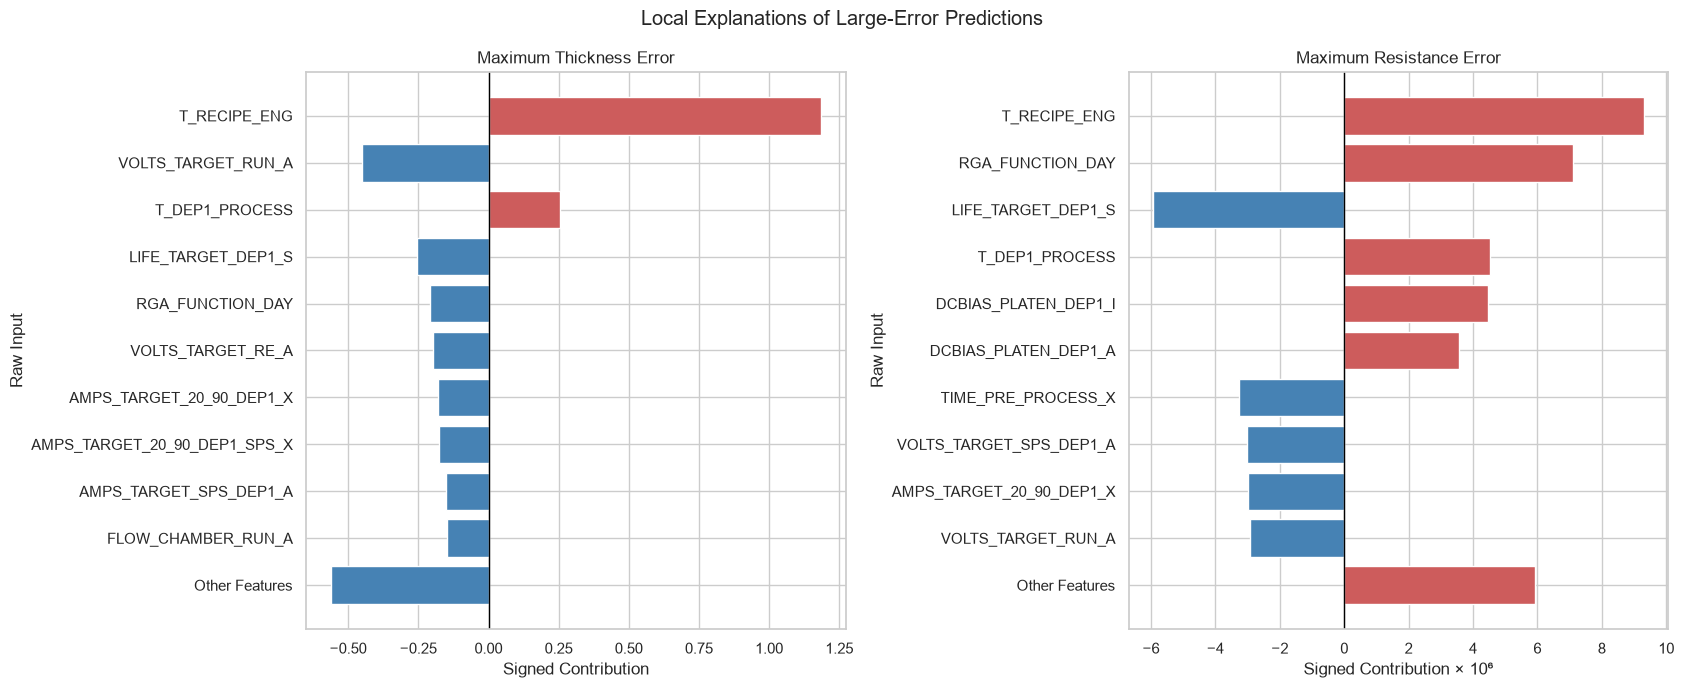

In [27]:
# Explain maximum-error diagnostic cases

fig, axes = plt.subplots(
    1, 2, figsize=(17, 7)
)

large_error_cases = [
    (
        "Maximum Thickness Error",
        "mean_thickness",
        1,
    ),

    (
        "Maximum Resistance Error",
        "mean_resistance",
        RESISTANCE_DISPLAY_SCALE,
    ),
]

for ax, (
    label,
    target,
    multiplier,
) in zip(axes, large_error_cases):

    explanation = case_explanations[label][target]

    plot_local_explanation(
        explanation,
        ax,
        label,
        multiplier=multiplier,
    )

plt.suptitle(
    "Local Explanations of Large-Error Predictions"
)

plt.tight_layout()
plt.show()

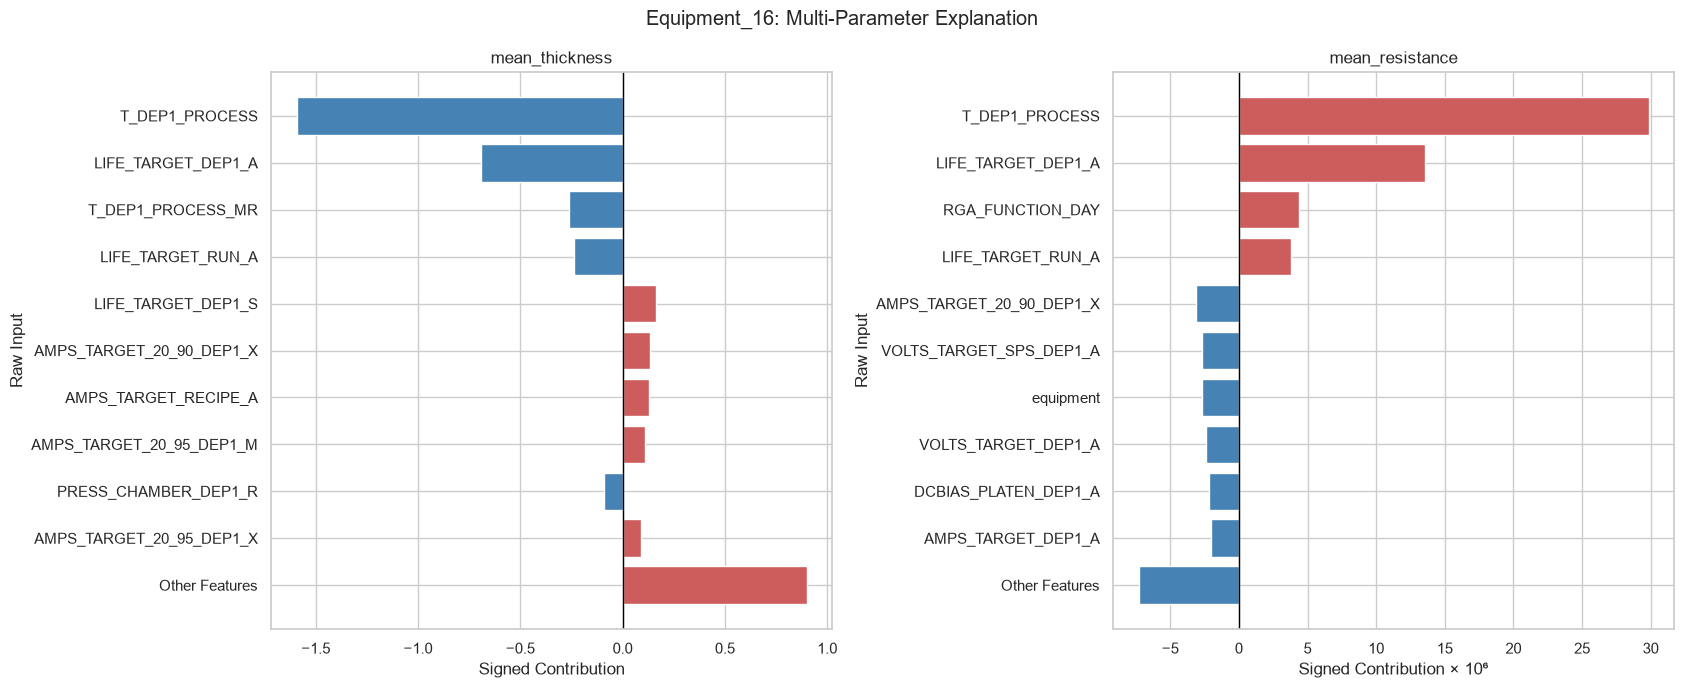

In [28]:
# Equipment_16 diagnostic explanation

label = "Equipment 16 Example"

fig, axes = plt.subplots(
    1, 2, figsize=(17, 7)
)

for ax, target in zip(axes, TARGETS):

    plot_local_explanation(
        case_explanations[label][target],

        ax,

        target,

        multiplier=(
            RESISTANCE_DISPLAY_SCALE
            if target == "mean_resistance"
            else 1
        ),
    )

plt.suptitle(
    "Equipment_16: Multi-Parameter Explanation"
)

plt.tight_layout()
plt.show()

## 13. Structured Engineering Explanation Evidence

Construct a machine-readable prediction
explanation payload for future application
and LLM integration.

Include model identifiers, predictions,
base predictions, signed contributions,
and interpretation restrictions.

Do not provide actual metrology as an input
to the prediction explanation.

The future LLM assistant will verbalise
the supplied evidence rather than perform
independent physical root-cause diagnosis.

In [29]:
# Construct a dual-target explanation payload

example_label = "Typical Joint Error"

example_index = case_indices[example_label]

example_record = val_df.iloc[example_index]

engineering_evidence = {
    "project": "STRATUM",

    "evidence_type": (
        "virtual_metrology_prediction_explanation"
    ),

    "example_partition": "original_validation",

    "example_case": example_label,

    "equipment": str(example_record["equipment"]),

    "measurement_units": (
        "Original dataset units; "
        "physical units not independently established"
    ),

    "predicted_properties": {
        "thickness": (
            case_explanations[
                example_label
            ]["mean_thickness"]
        ),

        "sheet_resistance": (
            case_explanations[
                example_label
            ]["mean_resistance"]
        ),
    },

    "input_quality": {
        "expected_apc_features": len(apc_features),

        "missing_apc_features": int(
            example_record[apc_features].isna().sum()
        ),
    },

    "interpretation_constraints": [
        "Explain only supplied numerical evidence.",

        "Feature contributions describe "
        "model predictions rather than causality.",

        "Do not infer physical equipment faults.",

        "Do not invent engineering units.",

        "Do not invent acceptance thresholds.",

        "Do not equate prediction error "
        "with wafer quality classification.",

        "Do not present feature contributions "
        "as calibrated prediction uncertainty.",

        "Recommend engineering investigation "
        "rather than automatic process adjustment.",
    ],
}

payload_text = json.dumps(
    engineering_evidence,
    indent=4,
    allow_nan=False,
)

print(payload_text)

{
    "project": "STRATUM",
    "evidence_type": "virtual_metrology_prediction_explanation",
    "example_partition": "original_validation",
    "example_case": "Typical Joint Error",
    "equipment": "equipment_12",
    "measurement_units": "Original dataset units; physical units not independently established",
    "predicted_properties": {
        "thickness": {
            "target": "mean_thickness",
            "method": "XGBoost native TreeSHAP",
            "output_scale": "Original dataset target scale",
            "aggregation": "Sum of transformed-feature attributions by originating raw input",
            "base_prediction": 152.33399963378906,
            "prediction": 148.85235595703125,
            "total_feature_contribution": -3.481880986792021,
            "top_features": [
                {
                    "feature": "T_RECIPE_ENG",
                    "input_value": 28.2044567925237,
                    "input_missing": false,
                    "contribution": 0

## 14. Inference-Time Explanation Robustness

Generate prediction explanations without
measured material-property targets.

Investigate synthetic missing sensor values
and unknown equipment identifiers.

Verify finite predictions and additive
reconstruction.

Successful explanation generation does
not establish predictive reliability
under unfamiliar process conditions.

In [30]:
# Synthetic explanation smoke tests

robustness_rows = []

for target in TARGETS:

    columns = input_columns[target]

    ordinary_input = (
        assessment_train_df[columns]
        .iloc[[0]]
        .copy()
    )

    missing_input = ordinary_input.copy()

    observed_features = [
        feature

        for feature in apc_features

        if pd.notna(
            ordinary_input.iloc[0][feature]
        )
    ]

    missing_features = observed_features[:3]

    assert len(missing_features) == 3

    for feature in missing_features:

        missing_input[feature] = np.nan

    scenarios = {
        "Ordinary Input": ordinary_input,

        "Additional Missing Sensors": missing_input,
    }

    if "equipment" in columns:

        unfamiliar_equipment = ordinary_input.copy()

        unfamiliar_equipment["equipment"] = (
            "equipment_unseen_test"
        )

        combined_input = missing_input.copy()

        combined_input["equipment"] = (
            "equipment_unseen_test"
        )

        scenarios.update({
            "Unknown Equipment": (
                unfamiliar_equipment
            ),

            "Missing Sensors + Unknown Equipment": (
                combined_input
            ),
        })

    for scenario, inputs in scenarios.items():

        assert "mean_thickness" not in inputs.columns

        assert "mean_resistance" not in inputs.columns

        explanation = explain_single_prediction(
            model=models[target],

            inputs=inputs,

            apc_features=apc_features,

            target=target,
        )

        assert np.isfinite(
            explanation["prediction"]
        )

        json.dumps(
            explanation,
            allow_nan=False,
        )

        robustness_rows.append({
            "Target": target,

            "Scenario": scenario,

            "Prediction": explanation["prediction"],

            "Reconstruction Error": (
                explanation["reconstruction_error"]
            ),

            "Positive Prediction": bool(
                explanation["prediction"] > 0
            ),

            "JSON Compatible": True,
        })

robustness_summary = pd.DataFrame(
    robustness_rows
)

display(robustness_summary)

assert len(robustness_summary) == 6

assert robustness_summary[
    "Positive Prediction"
].all()

print("Synthetic explanation smoke tests: PASSED")

,Target,Scenario,Prediction,Reconstruction Error,Positive Prediction,JSON Compatible
0,mean_thickness,Ordinary Input,152.189209,3.580071e-05,True,True
1,mean_thickness,Additional Missing Sensors,151.935211,4.518424e-07,True,True
2,mean_resistance,Ordinary Input,0.002885,9.081529e-11,True,True
3,mean_resistance,Additional Missing Sensors,0.002890,5.396537e-12,True,True
4,mean_resistance,Unknown Equipment,0.002885,9.077677e-11,True,True
5,mean_resistance,Missing Sensors + Unknown Equipment,0.002890,3.113177e-12,True,True


Synthetic explanation smoke tests: PASSED


## 15. Explanation Computation Benchmark

Measure repeated single-record TreeSHAP
explanation generation latency.

Include preprocessing, contribution calculation,
raw-input aggregation, and evidence construction.

Exclude network, database, and LLM generation time.

Report local CPU timings rather than
production service guarantees.

In [31]:
# Benchmark local explanation generation

explanation_benchmark_rows = []

EXPLANATION_REPETITIONS = 20

for target in TARGETS:

    record = (
        val_df[input_columns[target]]
        .iloc[[0]]
    )

    # Warm-up operations

    for _ in range(3):

        explain_single_prediction(
            models[target],
            record,
            apc_features,
            target,
        )

    elapsed_ms = []

    for _ in range(EXPLANATION_REPETITIONS):

        start = time.perf_counter()

        explain_single_prediction(
            models[target],
            record,
            apc_features,
            target,
        )

        elapsed_ms.append(
            (time.perf_counter() - start) * 1000
        )

    explanation_benchmark_rows.append({
        "Target": target,

        "Repetitions": EXPLANATION_REPETITIONS,

        "Median Explanation Latency (ms)": float(
            np.median(elapsed_ms)
        ),

        "P95 Explanation Latency (ms)": float(
            np.quantile(elapsed_ms, 0.95)
        ),

        "Minimum Explanation Latency (ms)": float(
            np.min(elapsed_ms)
        ),
    })

explanation_benchmarks = pd.DataFrame(
    explanation_benchmark_rows
)

display(explanation_benchmarks.round(6))

,Target,Repetitions,Median Explanation Latency (ms),P95 Explanation Latency (ms),Minimum Explanation Latency (ms)
0,mean_thickness,20,17.49135,24.004045,14.8433
1,mean_resistance,20,21.44920,30.090710,20.3712


## 16. Explainability Integrity Verification

Verify explanation coverage, transformed
feature dimensions, raw-input mappings,
numerical additivity, and JSON compatibility.

Confirm that both models retain their
frozen configurations.

A relative numerical tolerance of 1e-5
and an absolute tolerance of 1e-10 are
used for additive reconstruction checks.

The tolerance accommodates small floating-point
differences between native XGBoost contribution
calculations and ordinary predictions.

Actual reconstruction errors are retained.

No model predictions or feature contributions
are modified to enforce additivity.

Final held-out targets remain reserved.

In [32]:

# Final explainability integrity checks

SHAP_RECONSTRUCTION_RTOL = 1e-5

SHAP_RECONSTRUCTION_ATOL = 1e-10

for target in TARGETS:

    explanation = tree_explanations[target]

    grouped = raw_contribution_frames[target]

    assert (
        explanation["contributions"].shape[0]
        == 834
    )

    assert grouped.shape == (
        834,
        len(input_columns[target]),
    )

    assert np.isfinite(
        grouped.to_numpy()
    ).all()

    # GLOBAL ADDITIVE RECONSTRUCTION
    # Uses corrected TreeSHAP tolerance.

    np.testing.assert_allclose(
        (
            explanation["base_predictions"]
            + grouped.sum(axis=1).to_numpy()
        ),

        predictions[target],

        rtol=SHAP_RECONSTRUCTION_RTOL,

        atol=SHAP_RECONSTRUCTION_ATOL,
    )

    assert len(
        permutation_results[target]
    ) == len(input_columns[target])

    assert len(
        global_raw_shap[target]
    ) == len(input_columns[target])

    assert (
        model_configs[target]
        == selections[target]["selected_candidate"]
    )

    print(
        f"{target}: All global checks PASSED"
    )


# Verify individual explanations.

local_case_count = 0

for label, explanations in case_explanations.items():

    for target, explanation in explanations.items():

        reconstructed = (
            explanation["base_prediction"]

            + sum(
                feature["contribution"]

                for feature in explanation["top_features"]
            )

            + explanation["other_feature_contribution"]
        )

        # LOCAL ADDITIVE RECONSTRUCTION
        # Uses corrected TreeSHAP tolerance.

        np.testing.assert_allclose(
            reconstructed,

            explanation["prediction"],

            rtol=SHAP_RECONSTRUCTION_RTOL,

            atol=SHAP_RECONSTRUCTION_ATOL,
        )

        json.dumps(
            explanation,
            allow_nan=False,
        )

        local_case_count += 1

assert local_case_count == 8

assert len(robustness_summary) == 6

assert robustness_summary[
    "JSON Compatible"
].all()

assert robustness_summary[
    "Positive Prediction"
].all()

print(
    "\nLocal explanation cases verified:",
    local_case_count,
)

print(
    "Synthetic scenarios verified:",
    len(robustness_summary),
)

print(
    "TreeSHAP relative tolerance:",
    SHAP_RECONSTRUCTION_RTOL,
)

print(
    "TreeSHAP absolute tolerance:",
    SHAP_RECONSTRUCTION_ATOL,
)

print("Frozen model configurations: VERIFIED")

print("Explainability investigation: PASSED")

print("Final test targets not evaluated.")


mean_thickness: All global checks PASSED
mean_resistance: All global checks PASSED

Local explanation cases verified: 8
Synthetic scenarios verified: 6
TreeSHAP relative tolerance: 1e-05
TreeSHAP absolute tolerance: 1e-10
Frozen model configurations: VERIFIED
Explainability investigation: PASSED
Final test targets not evaluated.


## 17. Explainability Result Preservation

Preserve global importance results,
feature ranking comparisons, numerical
additivity diagnostics, local case studies,
and computational benchmarking.

Retain structured prediction-explanation
evidence for application development.

Record the numerical tolerance used for
additive reconstruction verification.

Do not export complete wafer-level
contribution matrices.

All numerical explanation values remain
in the original model output scale.

In [33]:

# Save explainability results

import platform
import os


def dataframe_to_json_records(frame):

    return (
        frame.astype(object)
        .where(pd.notna(frame), None)
        .to_dict(orient="records")
    )


def json_default(value):

    if isinstance(value, np.generic):

        return value.item()

    if isinstance(value, pd.Timestamp):

        return value.isoformat()

    raise TypeError(
        f"Unsupported JSON type: "
        f"{type(value).__name__}"
    )


explainability_results = {
    "project": "STRATUM",

    "experiment": "model_explainability",

    "dataset_sha256": current_sha256,

    "training_partition": "original_training",

    "explanation_partition": "original_validation",

    "training_records": len(assessment_train_df),

    "explanation_records": len(val_df),

    "random_state": RANDOM_STATE,

    "model_n_jobs": MODEL_N_JOBS,

    "permutation_n_jobs": PERMUTATION_N_JOBS,

    "permutation_repeats": PERMUTATION_REPEATS,

    "sklearn_version": sklearn.__version__,

    "xgboost_version": xgboost.__version__,

    "model_configurations": model_configs,

    "methods": [
        "Normalised XGBoost average gain",

        "Repeated raw-input permutation importance",

        "Native XGBoost TreeSHAP",
    ],

    "target_transformations": {
        "mean_thickness": None,

        "mean_resistance": (
            "Training-fitted StandardScaler "
            "with original-scale contribution conversion"
        ),
    },

    "raw_feature_aggregation": (
        "Sum signed transformed-feature "
        "contributions by originating raw input"
    ),

    "numerical_reconstruction_tolerance": {
        "relative_tolerance": SHAP_RECONSTRUCTION_RTOL,

        "absolute_tolerance": SHAP_RECONSTRUCTION_ATOL,

        "reason": (
            "Small floating-point differences between "
            "native XGBoost contributions and predictions"
        ),

        "contributions_modified": False,

        "predictions_modified": False,
    },

    "model_reproduction": (
        dataframe_to_json_records(
            reproduction_summary
        )
    ),

    "transformed_feature_summary": (
        dataframe_to_json_records(
            feature_schema_summary
        )
    ),

    "gain_importance": {
        target: dataframe_to_json_records(
            gain_importance[target]
        )

        for target in TARGETS
    },

    "gain_group_summary": (
        dataframe_to_json_records(
            gain_group_summary
        )
    ),

    "permutation_summary": (
        dataframe_to_json_records(
            permutation_summary
        )
    ),

    "permutation_importance": {
        target: dataframe_to_json_records(
            permutation_results[target]
        )

        for target in TARGETS
    },

    "tree_shap_additivity_summary": (
        dataframe_to_json_records(
            additivity_summary
        )
    ),

    "global_transformed_shap": {
        target: dataframe_to_json_records(
            global_transformed_shap[target]
        )

        for target in TARGETS
    },

    "global_raw_shap": {
        target: dataframe_to_json_records(
            global_raw_shap[target]
        )

        for target in TARGETS
    },

    "method_comparisons": {
        target: dataframe_to_json_records(
            method_comparisons[target]
        )

        for target in TARGETS
    },

    "method_agreement": (
        dataframe_to_json_records(
            method_agreement
        )
    ),

    "cross_target_comparison": {
        "shared_apc_features": len(
            cross_target_importance
        ),

        "spearman_rank_correlation": cross_target_rho,

        "top_10_overlap_count": len(
            shared_top_features
        ),

        "shared_top_features": shared_top_features,

        "feature_importance": (
            dataframe_to_json_records(
                cross_target_importance
            )
        ),
    },

    "contribution_relationship_summary": (
        dataframe_to_json_records(
            dependence_summary
        )
    ),

    "case_selection_policy": {
        "Typical Joint Error": (
            "Joint relative error closest "
            "to the validation median"
        ),

        "Maximum Thickness Error": (
            "Maximum validation thickness "
            "absolute error"
        ),

        "Maximum Resistance Error": (
            "Maximum validation resistance "
            "absolute error"
        ),

        "Equipment 16 Example": (
            "First chronological equipment_16 "
            "validation observation"
        ),
    },

    "local_case_summary": (
        dataframe_to_json_records(
            case_summary.drop(
                columns=[
                    "wafer_id",
                    "Validation Position",
                ]
            )
        )
    ),

    "local_case_explanations": case_explanations,

    "engineering_evidence_example": engineering_evidence,

    "synthetic_robustness": (
        dataframe_to_json_records(
            robustness_summary
        )
    ),

    "explanation_benchmarks": (
        dataframe_to_json_records(
            explanation_benchmarks
        )
    ),

    "benchmark_environment": {
        "platform": platform.platform(),

        "processor": platform.processor(),

        "logical_cpu_count": os.cpu_count(),

        "model_n_jobs": MODEL_N_JOBS,

        "explanation_repetitions": (
            EXPLANATION_REPETITIONS
        ),

        "warmup_repetitions": 3,
    },

    "limitations": [
        "Explainability uses the previously examined "
        "original-validation partition.",

        "Gain importance describes training "
        "split behaviour.",

        "Permutation may generate unrealistic "
        "combinations of correlated inputs.",

        "Correlated predictors can affect "
        "importance rankings.",

        "TreeSHAP uses the fitted tree model's "
        "native attribution procedure.",

        "Raw-input grouping is post-hoc "
        "attribution aggregation.",

        "Small floating-point reconstruction "
        "differences remain.",

        "Feature attribution does not establish "
        "physical causality.",

        "Selected local cases are illustrative.",

        "Largest-error cases are intentionally "
        "selected diagnostic examples.",

        "Local feature contributions do not "
        "represent calibrated uncertainty.",

        "Synthetic input checks do not establish "
        "predictive reliability.",

        "LLM evidence payload constructed but "
        "LLM integration not yet evaluated.",

        "Engineering acceptance thresholds "
        "are unavailable.",

        "Final held-out targets not evaluated.",
    ],
}

results_path = (
    results_dir / "model_explainability.json"
)

results_dir.mkdir(
    parents=True,
    exist_ok=True,
)

with open(
    results_path,
    "w",
    encoding="utf-8",
) as file:

    json.dump(
        explainability_results,

        file,

        indent=4,

        allow_nan=False,

        default=json_default,
    )

saved_results = json.loads(
    results_path.read_text(
        encoding="utf-8"
    )
)

assert (
    saved_results["dataset_sha256"]
    == current_sha256
)

assert (
    saved_results["model_configurations"]
    == model_configs
)

assert saved_results["explanation_records"] == 834

assert len(
    saved_results["local_case_explanations"]
) == 4

assert len(
    saved_results["synthetic_robustness"]
) == 6

assert (
    saved_results[
        "numerical_reconstruction_tolerance"
    ]["relative_tolerance"]
    == SHAP_RECONSTRUCTION_RTOL
)

print("Explainability results saved.")

print("ml/results/model_explainability.json")

print("\nExperiment JSON verification: PASSED")


Explainability results saved.
ml/results/model_explainability.json

Experiment JSON verification: PASSED


## 18. Final Explainability Summary

Generate a consolidated numerical summary
of model reproduction, global importance,
cross-method agreement, cross-target
predictor overlap, local explanations,
and computational benchmarking.

Report actual numerical reconstruction errors
and the applied verification tolerances.

In [34]:
# Generate final explainability research summary

print("=" * 70)

print("STRATUM - MODEL EXPLAINABILITY")

print("=" * 70)

print("\nMODEL REPRODUCTION")

display(reproduction_summary.round(10))

print("\nFEATURE SCHEMA")

display(feature_schema_summary)

print("\nGAIN GROUP SUMMARY")

display(gain_group_summary.round(6))

print("\nPERMUTATION SUMMARY")

display(permutation_summary)

for target in TARGETS:

    print("\n" + "-" * 65)

    print("TARGET:", target)

    print(
        "Model:",
        model_configs[target]["name"],
    )

    print("\nTOP 5 GAIN FEATURES")

    display(
        gain_importance[target]
        .head(5)
        .round(8)
    )

    print("\nTOP 5 PERMUTATION FEATURES")

    display(
        permutation_results[target]
        .head(5)
        .round(10)
    )

    print("\nTOP 5 RAW SHAP FEATURES")

    display(
        global_raw_shap[target]
        .head(5)
        .round(10)
    )

    print(
        "Maximum SHAP reconstruction error:",
        tree_explanations[target][
            "maximum_reconstruction_error"
        ],
    )

    print(
        "Mean SHAP reconstruction error:",
        tree_explanations[target][
            "mean_reconstruction_error"
        ],
    )

print("\nADDITIVITY VERIFICATION")

display(additivity_summary)

print(
    "Relative tolerance:",
    SHAP_RECONSTRUCTION_RTOL,
)

print(
    "Absolute tolerance:",
    SHAP_RECONSTRUCTION_ATOL,
)

print("\nEXPLAINABILITY METHOD AGREEMENT")

display(method_agreement)

print("\nCROSS-TARGET COMPARISON")

print(
    "Shared APC rank correlation:",
    cross_target_rho,
)

print(
    "Top 10 predictor overlap:",
    len(shared_top_features),
)

print(
    "Shared features:",
    shared_top_features,
)

print("\nLOCAL CASE STUDIES")

display(case_summary.round(10))

print("\nSYNTHETIC ROBUSTNESS")

display(robustness_summary)

print("\nEXPLANATION BENCHMARKING")

display(explanation_benchmarks.round(6))

print("\nRESEARCH STATUS")

print("Gain importance: COMPLETE")

print("Permutation importance: COMPLETE")

print("Native TreeSHAP: COMPLETE")

print("Local explanations: VERIFIED")

print("LLM evidence payload: PREPARED")

print("Final held-out evaluation: PENDING")

print("=" * 70)

STRATUM - MODEL EXPLAINABILITY

MODEL REPRODUCTION


,Target,Candidate,MAE,RMSE,R2,MAPE (%),Bias,Reference MAE,MAE Reproduction Difference,Reference R2,Training Time (s)
0,mean_thickness,XGB-4,1.072550,1.443448,0.650733,0.706370,-5.804488e-02,1.072550,0.0,0.650733,3.984979
1,mean_resistance,RES-XGB-2,0.000023,0.000031,0.633802,0.777569,-2.111000e-07,0.000023,0.0,0.633802,3.181357



FEATURE SCHEMA


,Target,Raw Inputs,Transformed Features,APC Measurements,Missingness Indicators,Equipment Metadata
0,mean_thickness,110,157,110,47,0
1,mean_resistance,111,173,110,47,16



GAIN GROUP SUMMARY


,Target,Group,Importance (%)
0,mean_thickness,APC Measurements,83.280892
1,mean_thickness,Missingness Indicators,16.719108
2,mean_resistance,APC Measurements,83.403034
3,mean_resistance,Equipment Metadata,8.958911
4,mean_resistance,Missingness Indicators,7.638056


... (21 outputs left out)

,Target,Scenario,Prediction,Reconstruction Error,Positive Prediction,JSON Compatible
0,mean_thickness,Ordinary Input,152.189209,3.580071e-05,True,True
1,mean_thickness,Additional Missing Sensors,151.935211,4.518424e-07,True,True
2,mean_resistance,Ordinary Input,0.002885,9.081529e-11,True,True
3,mean_resistance,Additional Missing Sensors,0.002890,5.396537e-12,True,True
4,mean_resistance,Unknown Equipment,0.002885,9.077677e-11,True,True
5,mean_resistance,Missing Sensors + Unknown Equipment,0.002890,3.113177e-12,True,True



EXPLANATION BENCHMARKING


,Target,Repetitions,Median Explanation Latency (ms),P95 Explanation Latency (ms),Minimum Explanation Latency (ms)
0,mean_thickness,20,17.49135,24.004045,14.8433
1,mean_resistance,20,21.44920,30.090710,20.3712



RESEARCH STATUS
Gain importance: COMPLETE
Permutation importance: COMPLETE
Native TreeSHAP: COMPLETE
Local explanations: VERIFIED
LLM evidence payload: PREPARED
Final held-out evaluation: PENDING



## 19. Findings and Engineering Interpretation

### Explainability Methodology

Both frozen XGBoost regression configurations
were reproduced using 3331 original training
observations.

The explainability analysis used 834
original-validation observations per model.

Three complementary methods were investigated:

- XGBoost average-gain importance.
- Repeated raw-input permutation importance.
- Native XGBoost TreeSHAP contributions.

No further model selection or feature
elimination was performed.

### Model Reproduction

Thickness configuration:

- Candidate: XGB-4.
- Raw inputs: 110.
- Equipment metadata: Excluded.
- Boosting rounds: 820.
- Validation MAE: 1.0725497319.
- Validation RMSE: 1.4434475152.
- Validation R2: 0.6507334197.
- Validation MAPE: 0.7063704940%.
- MAE reproduction difference: 0.0.

Resistance configuration:

- Candidate: RES-XGB-2.
- Raw inputs: 111.
- Equipment metadata: Included.
- Boosting rounds: 837.
- Target transformation: StandardScaler.
- Validation MAE: 2.2663523799e-05.
- Validation RMSE: 3.1490264046e-05.
- Validation R2: 0.6338022649.
- Validation MAPE: 0.7775693324%.
- MAE reproduction difference: 0.0.

Restoring the original training thread
configuration of n_jobs=-1 resolved the
observed model reproduction discrepancy.

Both models reproduced their recorded
validation metrics exactly.

### Transformed Feature Schema

Thickness preprocessing produced:

- APC representations: 110.
- Missingness indicators: 47.
- Equipment representations: 0.
- Total transformed features: 157.

Resistance preprocessing produced:

- APC representations: 110.
- Missingness indicators: 47.
- Equipment representations: 16.
- Total transformed features: 173.

Transformed features were mapped to
110 thickness and 111 resistance raw
input groups.

### Gain-Based Feature Importance

Leading thickness transformed features
and normalised average-gain percentages:

1. LIFE_TARGET_RUN_A: 9.416806%.
2. AMPS_TARGET_20_95_DEP1_SPS_X: 7.988101%.
3. LIFE_TARGET_DEP1_A: 4.982832%.
4. AMPS_TARGET_20_90_DEP1_SPS_X: 3.412507%.
5. Missingness indicator of
   AMPS_TARGET_RECIPE_A: 3.277356%.

Leading resistance transformed features:

1. LIFE_TARGET_RUN_A: 6.568265%.
2. LIFE_TARGET_DEP1_A: 5.744961%.
3. AMPS_TARGET_20_90_DEP1_SPS_X: 5.496673%.
4. VOLTS_TARGET_DEP1_5SEC_S: 5.462052%.
5. AMPS_TARGET_20_90_DEP1_SPS_M: 4.464545%.

LIFE_TARGET_RUN_A ranked first according
to average gain for both models.

Feature-group gain importance:

Thickness:

- APC measurements: 83.280892%.
- Missingness indicators: 16.719108%.

Resistance:

- APC measurements: 83.403034%.
- Missingness indicators: 7.638056%.
- Equipment metadata: 8.958911%.

Missingness indicators contributed a larger
share of normalised average gain in the
thickness model.

Gain importance describes tree-splitting
behaviour rather than explained target
variance or physical causality.

### Permutation Importance

Permutation importance was calculated on
the complete regression pipelines using
raw original-validation inputs.

Five repetitions were performed per feature.

Experimental coverage:

- Thickness shuffled-feature evaluations: 550.
- Resistance shuffled-feature evaluations: 555.
- Total shuffled-feature evaluations: 1105.

Leading thickness predictors and relative
MAE increases:

1. T_DEP1_PROCESS: 89.590677%.
2. T_RECIPE_ENG: 46.609537%.
3. LIFE_TARGET_DEP1_A: 16.634449%.
4. LIFE_TARGET_DEP1_S: 14.272621%.
5. VOLTS_TARGET_RUN_A: 10.294284%.

Leading resistance predictors:

1. T_DEP1_PROCESS: 72.125711%.
2. T_RECIPE_ENG: 42.262244%.
3. LIFE_TARGET_DEP1_S: 12.192805%.
4. LIFE_TARGET_DEP1_A: 12.078759%.
5. VOLTS_TARGET_SPS_DEP1_A: 5.948198%.

Thickness importance distribution:

- Positive features: 77.
- Negative features: 28.
- Zero-importance features: 5.
- Computation time: 13.120155 seconds.

Resistance importance distribution:

- Positive features: 82.
- Negative features: 24.
- Zero-importance features: 5.
- Computation time: 15.682522 seconds.

T_DEP1_PROCESS exhibited the largest
mean MAE increase for both models.

Absolute mean MAE increases:

- Thickness: 0.9609045711.
- Resistance: 1.6346227743e-05.

Negative importance values were retained.

Correlated inputs can substitute for
one another and influence importance estimates.

Permutation may generate unrealistic
combinations of manufacturing inputs.

### Native TreeSHAP Contributions

Native XGBoost TreeSHAP contributions were
calculated for both fitted models using
pred_contribs=True and approx_contribs=False.

Thickness base prediction:

152.3339996338.

Resistance base prediction:

0.002894505100844.

The resistance target transformer contained:

- Training mean: 0.002894437509842.
- Training scale: 5.3341696886e-05.

Resistance contributions were converted
from standardised output space into the
original dataset target scale.

Feature contributions and baseline terms
were transformed consistently.

Transformed features were aggregated by
their originating raw input.

The aggregation preserves signed additive
contributions but is not equivalent to
recomputed grouped Shapley values.

### Numerical Reconstruction Verification

The initial relative reconstruction tolerance
of 1e-6 revealed small numerical differences
between summed native XGBoost contributions
and ordinary model predictions.

Diagnostic results under the original
tolerance:

- Thickness failures: 194.
- Resistance failures: 0.

The thickness booster and complete
pipeline predictions matched exactly
in the diagnostic comparison.

The resistance booster-to-pipeline maximum
difference was approximately 2.220891e-10.

The updated additive reconstruction
verification used:

- Relative tolerance: 1e-5.
- Absolute tolerance: 1e-10.

Both models passed the updated tolerance
across all 834 validation observations.

Thickness reconstruction errors:

- Maximum: 3.4006848728e-04.
- Mean: 1.0104500267e-04.
- Maximum relative error: 2.2756750866e-06.

Resistance reconstruction errors:

- Maximum: 2.6868589081e-10.
- Mean: 1.0677740663e-10.
- Maximum relative error: 9.3361540309e-08.

The small discrepancies are consistent with
floating-point differences between the
numerical prediction and contribution
calculation procedures.

No feature contributions, model predictions,
or frozen hyperparameters were modified
to enforce additivity.

Ordinary prediction comparisons and
target-scaler parameter checks retained
their original tolerances.

### Global Predictor Importance

Leading thickness raw-input TreeSHAP
importance values:

1. T_DEP1_PROCESS: 11.936413%.
2. T_RECIPE_ENG: 10.743814%.
3. LIFE_TARGET_DEP1_A: 5.137178%.
4. LIFE_TARGET_DEP1_S: 4.774095%.
5. VOLTS_TARGET_RUN_A: 4.709542%.

Leading resistance raw-input TreeSHAP
importance values:

1. T_DEP1_PROCESS: 10.596889%.
2. T_RECIPE_ENG: 9.732319%.
3. RGA_FUNCTION_DAY: 4.787632%.
4. LIFE_TARGET_DEP1_A: 4.041216%.
5. LIFE_TARGET_DEP1_S: 4.015865%.

Both permutation importance and TreeSHAP
identified T_DEP1_PROCESS and T_RECIPE_ENG
as the two leading raw inputs for both
material-property models.

RGA_FUNCTION_DAY ranked third for resistance
and tenth for thickness in the global
TreeSHAP rankings.

This variable was also identified during
the earlier univariate statistical
correlation investigation.

These findings provide complementary
descriptive evidence of predictive
relevance.

Relative TreeSHAP importance represents
normalised mean absolute contribution
rather than explained target variance.

### Explainability Method Agreement

Thickness Spearman rank correlations:

- Gain versus Permutation: 0.481825.
- Gain versus SHAP: 0.685574.
- Permutation versus SHAP: 0.687637.

Thickness top-10 overlaps:

- Gain versus Permutation: 4.
- Gain versus SHAP: 4.
- Permutation versus SHAP: 9.

Resistance Spearman rank correlations:

- Gain versus Permutation: 0.614955.
- Gain versus SHAP: 0.759327.
- Permutation versus SHAP: 0.694828.

Resistance top-10 overlaps:

- Gain versus Permutation: 4.
- Gain versus SHAP: 2.
- Permutation versus SHAP: 8.

Permutation and TreeSHAP exhibited
substantial agreement among the leading
raw predictors.

Differences between methods reflect their
distinct definitions of feature importance.

The comparisons are descriptive rather
than formal statistical significance tests.

### Cross-Target Predictor Comparison

The rankings of 110 shared APC inputs
were compared across both models.

Cross-target Spearman rank correlation:

0.8501807821.

Shared top-10 APC predictors: 8 of 10.

Shared leading predictors:

- AMPS_TARGET_20_90_DEP1_X.
- LIFE_TARGET_DEP1_A.
- LIFE_TARGET_DEP1_S.
- RGA_FUNCTION_DAY.
- T_DEP1_PROCESS.
- T_RECIPE_ENG.
- VOLTS_TARGET_RE_A.
- VOLTS_TARGET_RUN_A.

Despite independent model selection,
different input configurations and
different output transformations,
the models exhibit substantial similarity
in global APC importance rankings.

Equipment metadata was analysed separately
because it is not a thickness-model input.

The results support the investigation
of a shared multi-parameter virtual
metrology framework.

They do not establish common physical
causal mechanisms.

### Feature Value and Contribution Relationships

T_DEP1_PROCESS exhibited contrasting
contribution patterns across targets.

Higher observed values were generally
associated with more positive thickness
contributions and more negative resistance
contributions.

These patterns are directionally consistent
with the negative thickness-resistance
relationship identified during exploratory
data analysis.

T_RECIPE_ENG exhibited substantial
contribution variability within a narrow
range of commonly observed raw values.

An isolated extreme raw value was also
visible in the contribution scatterplots.

LIFE_TARGET_DEP1_A exhibited nonlinear
thickness contribution behaviour,
particularly near its lower observed range.

RGA_FUNCTION_DAY exhibited positive
resistance contributions throughout the
evaluated validation population.

The observed relationships describe fitted
model behaviour.

They do not establish physical process
response curves or intervention effects.

### Individual Wafer Case Studies

Four diagnostic cases were investigated.

Both material-property models were explained
for each case, producing eight verified
local prediction explanations.

Typical joint prediction error:

- Equipment: equipment_12.
- Actual thickness: 148.0641087680.
- Predicted thickness: 148.8523559570.
- Thickness absolute error: 0.7882471890.
- Actual resistance: 0.002985871448.
- Predicted resistance: 0.002968537621.
- Resistance absolute error: 1.7333826354e-05.

Leading thickness contributions:

- T_RECIPE_ENG: +0.763955.
- T_DEP1_PROCESS: -0.472235.
- VOLTS_TARGET_RUN_A: -0.467761.

Leading resistance contributions:

- Equipment: +1.6962935993e-05.
- T_RECIPE_ENG: -1.3467490674e-05.
- RGA_FUNCTION_DAY: +8.2447875455e-06.

Maximum thickness error:

- Equipment: equipment_6.
- Actual thickness: 145.6254544990.
- Predicted thickness: 151.4467163086.
- Absolute error: 5.8212618095.
- Leading contribution: T_RECIPE_ENG.
- Contribution: +1.1855505414.

Maximum resistance error:

- Equipment: equipment_15.
- Actual resistance: 0.003109253581.
- Predicted resistance: 0.002911276650.
- Absolute error: 1.9797693176e-04.
- Leading contribution: T_RECIPE_ENG.
- Contribution: +9.3026108045e-06.

Equipment_16 example:

- Actual thickness: 150.3173893176.
- Predicted thickness: 150.9747009277.
- Thickness absolute error: 0.6573116101.
- Actual resistance: 0.002925698106.
- Predicted resistance: 0.002923680004.
- Resistance absolute error: 2.0181021129e-06.

T_DEP1_PROCESS contributions for this case:

- Thickness: -1.5929112434.
- Resistance: +2.9840233469e-05.

LIFE_TARGET_DEP1_A contributions:

- Thickness: -0.6943893433.
- Resistance: +1.3554563666e-05.

The opposing contribution directions
provide an illustrative example of the
multi-parameter model behaviour.

This individual observation does not
establish the cause of systematic
equipment-level prediction bias.

Local contributions explain predictions
rather than the physical causes of
prediction errors.

### Inference-Time Robustness

Six applicable synthetic scenarios were
investigated across the two models:

- Thickness ordinary input.
- Thickness additional missing sensors.
- Resistance ordinary input.
- Resistance additional missing sensors.
- Resistance unknown equipment.
- Resistance missing sensors and
  unknown equipment.

All six scenarios returned finite positive
predictions and JSON-compatible explanations.

Additive reconstruction checks passed.

Measured material-property targets were
not required for explanation generation.

Synthetic checks establish numerical
input handling rather than accuracy
under unseen manufacturing conditions.

### Computational Considerations

Global contribution calculation and
associated preprocessing and reconstruction
verification for 834 observations:

- Thickness: 0.422555 seconds.
- Resistance: 0.334916 seconds.

Single-record explanation benchmarks
used 20 repetitions per model.

Thickness:

- Median latency: 15.809800 ms.
- P95 latency: 17.119235 ms.
- Minimum latency: 14.658700 ms.

Resistance:

- Median latency: 24.005350 ms.
- P95 latency: 25.005435 ms.
- Minimum latency: 21.425400 ms.

The measured latency includes preprocessing,
native TreeSHAP calculation, raw-input
aggregation and local evidence construction.

The results support the feasibility of
on-demand explanation generation within
a CPU-based application.

Local explanation latency does not include
network communication, database queries,
or LLM inference.

### LLM Integration Preparation

A structured dual-target explanation
payload was constructed.

The payload includes:

- Model identifiers.
- Predicted material properties.
- Base predictions.
- Signed feature contributions.
- Remaining feature contribution.
- Missing input information.
- Interpretation restrictions.

The LLM assistant will be grounded in
this evidence rather than independently
inventing engineering explanations.

Actual LLM integration and factual
evaluation remain application-development
tasks.

### Result Preservation

The reusable explanation engine is stored in:

ml/explainability.py

The complete experiment is preserved in:

ml/results/model_explainability.json

The result file includes global importance,
individual explanations, computational
benchmarks, numerical reconstruction tolerances,
and structured engineering evidence.

The complete wafer-by-feature contribution
matrices were not exported.

### Limitations

- Explainability uses the previously examined
  original-validation population.
- Feature attribution does not establish
  physical causality.
- Correlated inputs affect interpretation.
- Permutation can create unrealistic inputs.
- Raw-input grouping is post-hoc aggregation.
- Small floating-point reconstruction
  differences remain.
- Local case studies are illustrative.
- Feature contributions are not uncertainty
  estimates or process acceptance limits.
- Prediction-time feature availability
  requires further verification.
- Official engineering measurement units
  and thresholds are not established.
- Computational timings are machine-specific.
- Actual LLM integration has not been evaluated.
- Final held-out test targets remain reserved.

### Conclusion

The investigation extends STRATUM from
predictive virtual metrology to explainable
multi-parameter virtual metrology.

Both frozen regression models were reproduced
with no recorded validation MAE discrepancy.

Complementary permutation and TreeSHAP
analyses identified T_DEP1_PROCESS and
T_RECIPE_ENG as the leading raw-input
predictors for both material properties.

Cross-target importance rankings achieved
a Spearman correlation of approximately
0.850181 with eight shared top-10 APC
predictors.

Native TreeSHAP enabled original-scale
individual prediction explanations without
introducing an additional SHAP dependency.

Global and local reconstruction checks
passed the documented numerical tolerances.

The reusable explanation engine and
structured evidence payload provide the
foundation for the STRATUM application
and LLM-powered engineering assistant.

The next stage performs final held-out
evaluation of both frozen regression models.